# Retail Demand Forecasting & Inventory Decision Support

End-to-end notebook: data audit, EDA, leakage-safe features (91+ day lags), time-series CV with a final hold-out, baselines vs. ETS / SARIMAX / Prophet / LightGBM, error diagnostics, an assumption-based inventory simulation, and export of the files used by the Streamlit app in `app/`.

**Data:** Kaggle *Store Item Demand Forecasting Challenge* `train.csv` (not included; see `data/README.md`).
**Setup:** set `PROJECT_DIR` in the config cell. The first cell mounts Google Drive and is only needed on Colab; skip it when running locally.
**Note:** all cost figures are illustrative assumptions, not real savings. See the project README for results and limitations.

In [ ]:
# mount drive
from google.colab import drive
drive.mount("/content/drive")

# check the file is there
!ls -lh "/content/drive/MyDrive/demand_forecasting/"

Mounted at /content/drive
total 91M
drwx------ 2 root root 4.0K Oct 15 11:27 app
-rw------- 1 root root  21K Oct 15 11:18 calibration_lgbm_ratio.pkl
-rw------- 1 root root  14M Oct 15 11:00 diagnostic_table.pkl
-rw------- 1 root root  24M Oct 14 22:23 features.parquet
drwx------ 2 root root 4.0K Oct 14 22:19 figures
-rw------- 1 root root 5.8M Oct 15 11:04 holdout_predictions.pkl
-rw------- 1 root root  620 Oct 15 11:18 inventory_results_matched_service.csv
-rw------- 1 root root  896 Oct 15 11:18 inventory_results_target_service.csv
-rw------- 1 root root  270 Oct 15 11:18 inventory_sensitivity.csv
-rw------- 1 root root  32M Oct 15 10:44 oof_predictions.pkl
-rw------- 1 root root  22K Oct 15 11:00 series_error_stats.pkl
-rw------- 1 root root  17M Oct 14 22:11 train.csv


In [ ]:
# imports + config
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")

PROJECT_DIR = Path("/content/drive/MyDrive/demand_forecasting")

CFG = {
    "data_path": PROJECT_DIR / "train.csv",  # folder in my drive
    "horizon_days": 90,
    "random_seed": 42,
    # cost assumptions, placeholders for now (not real numbers). filled in at the inventory part
    "assumptions": {
        "unit_holding_cost": None,
        "unit_stockout_cost": None,
        "service_level": None,
        "lead_time_days": None,
    },
}
np.random.seed(CFG["random_seed"])

In [ ]:
# load + check the data
def load_sales(path: Path) -> pd.DataFrame:
    """read train.csv and sort by store, item, date (the lags need this order)"""
    df = pd.read_csv(
        path,
        parse_dates=["date"],
        dtype={"store": "int8", "item": "int8", "sales": "int16"},
    )
    return df.sort_values(["store", "item", "date"]).reset_index(drop=True)


def sanity_report(df: pd.DataFrame) -> None:
    """basic checks on the raw data"""
    n_days = df["date"].nunique()
    n_series = df.groupby(["store", "item"]).ngroups

    print(f"Shape:            {df.shape}")
    print(f"Date range:       {df['date'].min().date()} -> {df['date'].max().date()}")
    print(f"Unique days:      {n_days}")
    print(f"Stores / Items:   {df['store'].nunique()} / {df['item'].nunique()}")
    print(f"Series (store x item): {n_series}")
    print(f"Missing values:   {int(df.isna().sum().sum())}")
    print(f"Duplicate (date, store, item) rows: "
          f"{int(df.duplicated(['date', 'store', 'item']).sum())}")

    # panel is complete if every series has a row for every day
    expected_rows = n_days * n_series
    print(f"Expected rows if panel is complete: {expected_rows} | "
          f"actual: {len(df)} | complete: {expected_rows == len(df)}")

    # any skipped days?
    full_range = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
    print(f"Calendar contiguous: {len(full_range) == n_days}")

    print(f"Sales min/median/max: "
          f"{df['sales'].min()} / {df['sales'].median()} / {df['sales'].max()}")


sales = load_sales(CFG["data_path"])
sanity_report(sales)
sales.head()

Shape:            (913000, 4)
Date range:       2013-01-01 -> 2017-12-31
Unique days:      1826
Stores / Items:   10 / 50
Series (store x item): 500
Missing values:   0
Duplicate (date, store, item) rows: 0
Expected rows if panel is complete: 913000 | actual: 913000 | complete: True
Calendar contiguous: True
Sales min/median/max: 0 / 47.0 / 231


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [ ]:
# --- eda helpers + audit ---
FIG_DIR = PROJECT_DIR / "figures"  # for the readme later
FIG_DIR.mkdir(exist_ok=True)

def save_fig(name: str) -> None:
    """save the figure to the figures folder and show it"""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def audit_report(df: pd.DataFrame) -> None:
    """extra quality checks (negatives, zeros)"""
    zeros_per_series = df.groupby(["store", "item"])["sales"].apply(lambda x: (x == 0).sum())
    print("Negative sales rows:        ", int((df["sales"] < 0).sum()))
    print("Zero-sales rows:            ", int((df["sales"] == 0).sum()),
          f"({100 * (df['sales'] == 0).mean():.4f}% of all rows)")
    print("Series with >=1 zero day:   ", int((zeros_per_series > 0).sum()))
    print("Max zero days in one series:", int(zeros_per_series.max()))
    print("\nSales distribution:")
    print(df["sales"].describe().round(2))

audit_report(sales)

# copy with year / month / weekday columns, only for the plots
eda = sales.assign(
    year=sales["date"].dt.year,
    month=sales["date"].dt.month,
    dow=sales["date"].dt.dayofweek,  # 0 = monday
)

Negative sales rows:         0
Zero-sales rows:             1 (0.0001% of all rows)
Series with >=1 zero day:    1
Max zero days in one series: 1

Sales distribution:
count    913000.00
mean         52.25
std          28.80
min           0.00
25%          30.00
50%          47.00
75%          70.00
max         231.00
Name: sales, dtype: float64


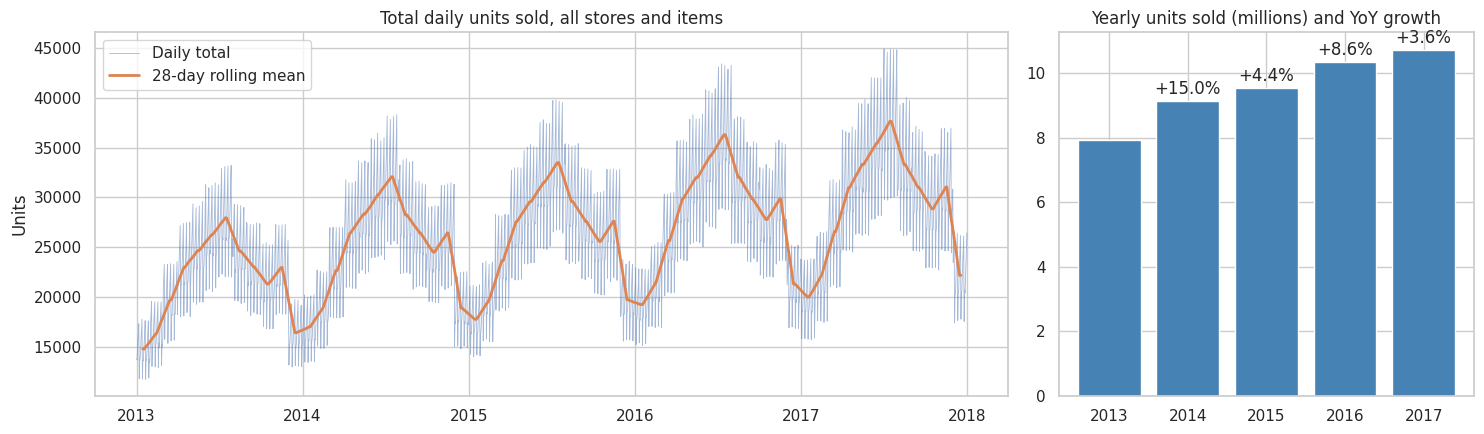

In [ ]:
# --- trend ---
daily_total = sales.groupby("date")["sales"].sum()
yearly = eda.groupby("year")["sales"].sum()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})

ax[0].plot(daily_total.index, daily_total.values, lw=0.6, alpha=0.5, label="Daily total")
ax[0].plot(daily_total.rolling(28, center=True).mean(), lw=2, label="28-day rolling mean")
ax[0].set_title("Total daily units sold, all stores and items")
ax[0].set_ylabel("Units"); ax[0].legend()

bars = ax[1].bar(yearly.index.astype(str), yearly.values / 1e6, color="steelblue")
growth = yearly.pct_change() * 100
ax[1].bar_label(bars, labels=[f"{g:+.1f}%" if pd.notna(g) else "" for g in growth], padding=2)
ax[1].set_title("Yearly units sold (millions) and YoY growth")
save_fig("01_trend")

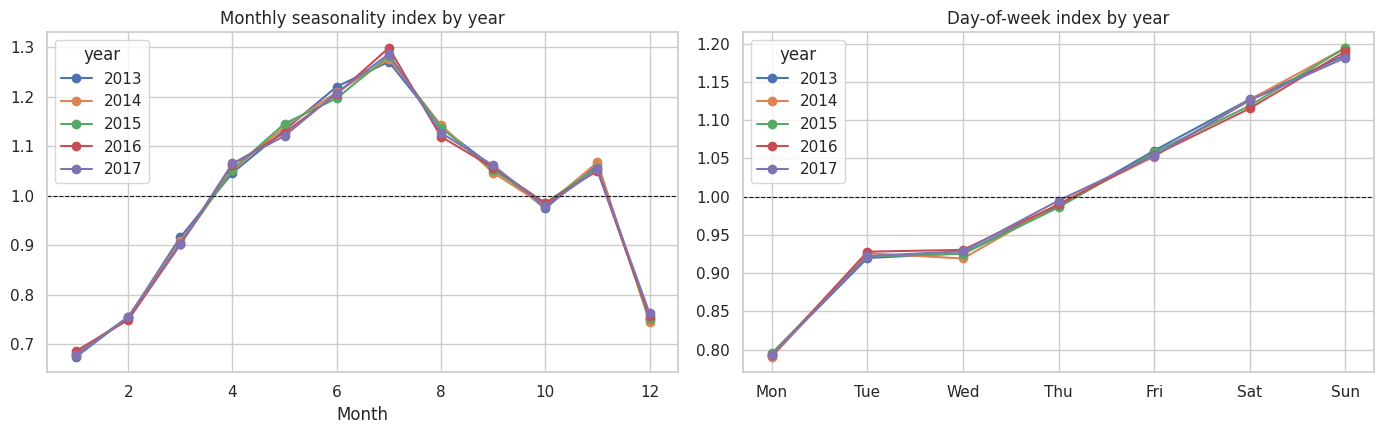

In [ ]:
# --- seasonality ---
# index = average for that month/weekday divided by the average for the year
# (1.2 means 20% above a normal day). dividing by the yearly average removes the trend,
# so the shapes of different years can be compared
month_idx = eda.groupby(["year", "month"])["sales"].mean().unstack(0)
month_idx = month_idx / month_idx.mean()

dow_idx = eda.groupby(["year", "dow"])["sales"].mean().unstack(0)
dow_idx = dow_idx / dow_idx.mean()
dow_idx.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
month_idx.plot(ax=ax[0], marker="o")
ax[0].axhline(1, color="k", lw=0.8, ls="--")
ax[0].set_title("Monthly seasonality index by year"); ax[0].set_xlabel("Month")

dow_idx.plot(ax=ax[1], marker="o")
ax[1].axhline(1, color="k", lw=0.8, ls="--")
ax[1].set_title("Day-of-week index by year")
save_fig("02_seasonality")

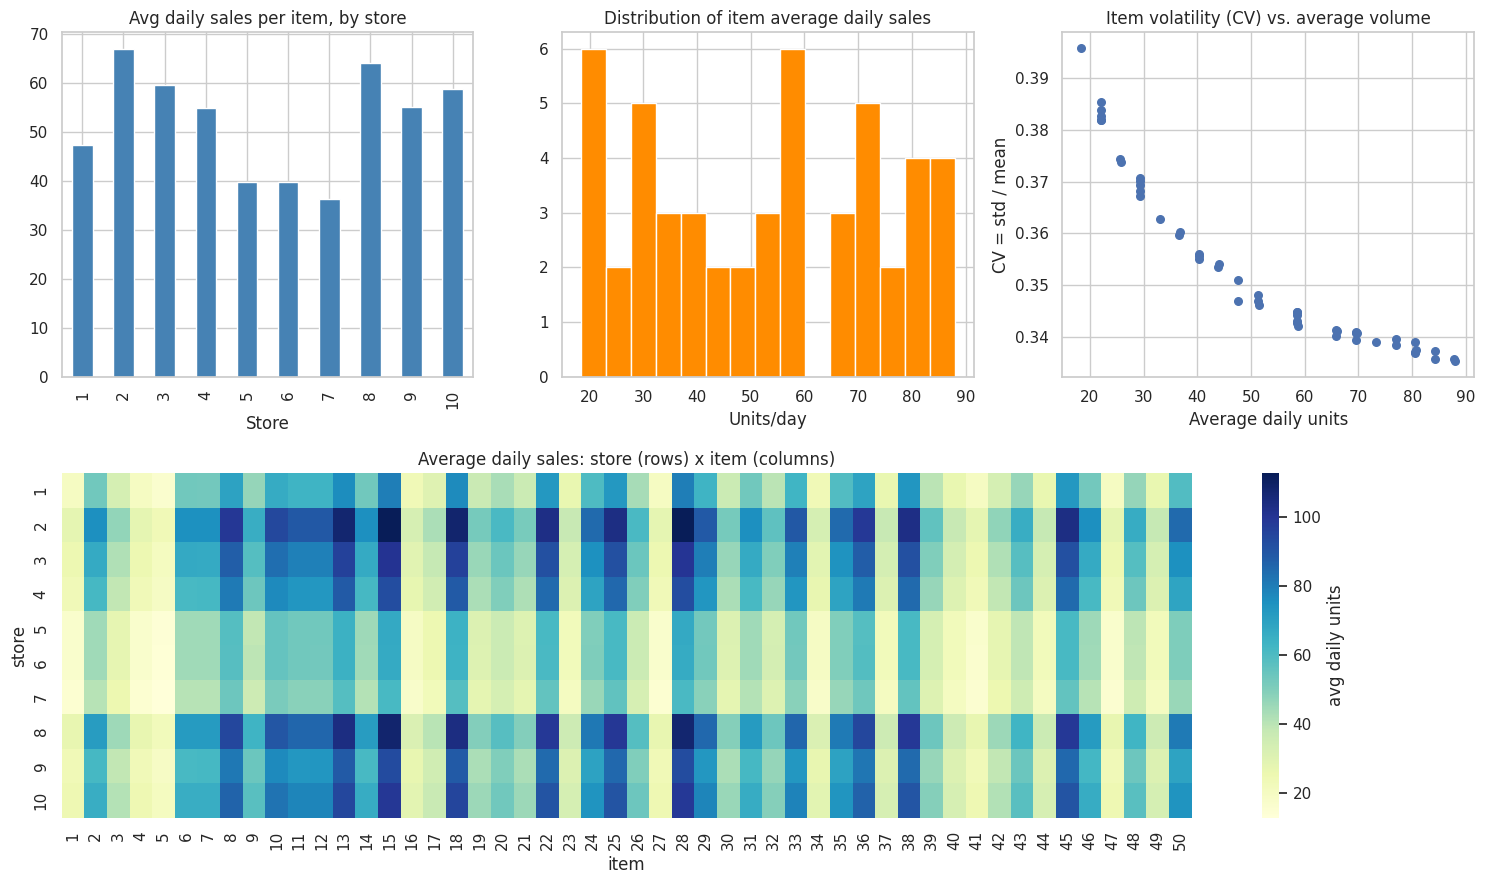

{1: 47.3, 2: 67.0, 3: 59.5, 4: 54.9, 5: 39.8, 6: 39.7, 7: 36.4, 8: 64.1, 9: 55.0, 10: 58.7}
count    50.000
mean      0.353
std       0.016
min       0.335
25%       0.340
50%       0.347
75%       0.366
max       0.396
Name: cv, dtype: float64


In [ ]:
# --- store / item differences ---
store_mean = sales.groupby("store")["sales"].mean()
item_stats = sales.groupby("item")["sales"].agg(["mean", "std"])
item_stats["cv"] = item_stats["std"] / item_stats["mean"]  # cv = std / mean
heat = sales.pivot_table(index="item", columns="store", values="sales", aggfunc="mean")

fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(2, 3)
a1 = fig.add_subplot(gs[0, 0]); a2 = fig.add_subplot(gs[0, 1])
a3 = fig.add_subplot(gs[0, 2]); a4 = fig.add_subplot(gs[1, :])

store_mean.plot.bar(ax=a1, color="steelblue")
a1.set_title("Avg daily sales per item, by store"); a1.set_xlabel("Store")

a2.hist(item_stats["mean"], bins=15, color="darkorange", edgecolor="white")
a2.set_title("Distribution of item average daily sales"); a2.set_xlabel("Units/day")

a3.scatter(item_stats["mean"], item_stats["cv"], s=30)
a3.set_title("Item volatility (CV) vs. average volume")
a3.set_xlabel("Average daily units"); a3.set_ylabel("CV = std / mean")

sns.heatmap(heat.T, ax=a4, cmap="YlGnBu", cbar_kws={"label": "avg daily units"})
a4.set_title("Average daily sales: store (rows) x item (columns)")
save_fig("03_store_item")

print(store_mean.round(1).to_dict())
print(item_stats["cv"].describe().round(3))

Flagged: 562 rows (0.062% of all rows)
Flagged per store: {1: 47, 2: 55, 3: 60, 4: 51, 5: 63, 6: 70, 7: 64, 8: 46, 9: 52, 10: 54}
Max series flagged on any single date: 7 of 500


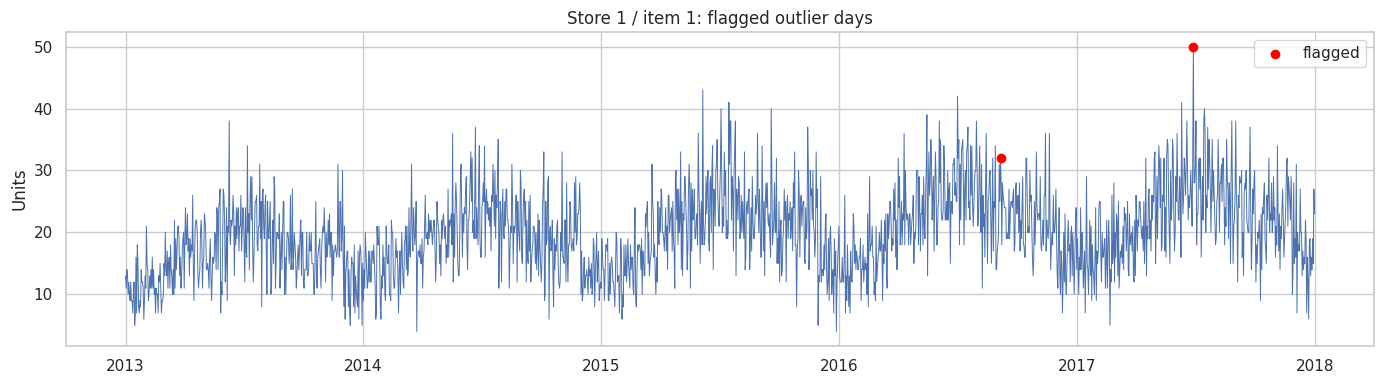

In [ ]:
# --- anomalies ---
def flag_anomalies(df: pd.DataFrame, window: int = 28, z_thresh: float = 4.0) -> pd.DataFrame:
    # take out the weekday effect first, otherwise every sunday looks like an outlier
    # then compare each day to a centered 28 day median and scale by the MAD
    # eda only. the centered window looks at future days so this can't be a feature
    dow = df["date"].dt.dayofweek
    dow_idx = df.groupby(dow)["sales"].transform("mean") / df["sales"].mean()
    adj = df["sales"] / dow_idx
    keys = [df["store"], df["item"]]

    local_med = adj.groupby(keys).transform(
        lambda x: x.rolling(window, center=True, min_periods=window // 2).median()
    )
    resid = adj - local_med
    med = resid.groupby(keys).transform("median")
    mad = (resid - med).abs().groupby(keys).transform("median")
    z = 0.6745 * (resid - med) / mad.replace(0, np.nan)
    return df.assign(robust_z=z)[lambda d: d["robust_z"].abs() > z_thresh]

anom = flag_anomalies(sales)
print(f"Flagged: {len(anom)} rows ({100 * len(anom) / len(sales):.3f}% of all rows)")
print("Flagged per store:", anom.groupby("store").size().to_dict())
print("Max series flagged on any single date:",
      int(anom.groupby("date").size().max()), "of 500")

# plot the worst one
ex = anom.sort_values("robust_z", ascending=False).iloc[0]
one = sales[(sales["store"] == ex["store"]) & (sales["item"] == ex["item"])]
hits = anom[(anom["store"] == ex["store"]) & (anom["item"] == ex["item"])]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(one["date"], one["sales"], lw=0.7)
ax.scatter(hits["date"], hits["sales"], color="red", zorder=3, label="flagged")
ax.set_title(f"Store {int(ex['store'])} / item {int(ex['item'])}: flagged outlier days")
ax.set_ylabel("Units"); ax.legend()
save_fig("04_anomalies")

In [ ]:
# --- features: config + calendar ---
from pandas.tseries.holiday import USFederalHolidayCalendar

FE = {
    # smallest lag allowed is horizon + 1. 91 days = 13 weeks so the weekday lines up
    "min_lag": CFG["horizon_days"] + 1,
    "lags": [91, 98, 105, 112, 182, 364],  # all multiples of 7
    "roll_windows": [7, 28, 91],
}

# stop right away if the lags get edited into something leaky
assert all(l >= FE["min_lag"] for l in FE["lags"]), "A lag is shorter than the horizon -> leakage!"
assert FE["min_lag"] % 7 == 0, "min_lag should be a multiple of 7 to keep weekday alignment"


def add_calendar_features(df: pd.DataFrame) -> pd.DataFrame:
    """calendar features (known in advance, so no leakage risk)"""
    d = df["date"]
    out = df.copy()
    out["dow"] = d.dt.dayofweek.astype("int8")  # 0 = monday
    out["is_weekend"] = (out["dow"] >= 5).astype("int8")
    out["day_of_month"] = d.dt.day.astype("int8")
    out["week_of_year"] = d.dt.isocalendar().week.astype("int8")
    out["month"] = d.dt.month.astype("int8")
    out["quarter"] = d.dt.quarter.astype("int8")
    out["day_of_year"] = d.dt.dayofyear.astype("int16")
    out["is_month_start"] = d.dt.is_month_start.astype("int8")
    out["is_month_end"] = d.dt.is_month_end.astype("int8")

    # sin/cos versions, mostly useful for linear models
    out["dow_sin"] = np.sin(2 * np.pi * out["dow"] / 7).astype("float32")
    out["dow_cos"] = np.cos(2 * np.pi * out["dow"] / 7).astype("float32")
    out["doy_sin"] = np.sin(2 * np.pi * out["day_of_year"] / 365.25).astype("float32")
    out["doy_cos"] = np.cos(2 * np.pi * out["day_of_year"] / 365.25).astype("float32")

    # assuming US federal holidays since I don't know the country
    # (range goes past the training end so future dates get the flag too)
    hol = USFederalHolidayCalendar().holidays(start="2012-12-01", end="2018-12-31")
    out["is_us_holiday"] = d.isin(hol).astype("int8")
    return out

In [ ]:
# --- lag + rolling features ---
def add_lag_roll_features(df: pd.DataFrame, lags, windows, min_lag) -> pd.DataFrame:
    # wide table (date x series) so a shift never leaves its own series
    # shifting the long table without a groupby would mix the end of one series into the next one
    # rolling windows use the series shifted by min_lag, so they end at t - min_lag
    wide = df.pivot(index="date", columns=["store", "item"], values="sales").astype("float32")
    n_days, n_series = wide.shape

    # results get copied back by position, so check the row order matches
    exp_store = np.repeat(wide.columns.get_level_values(0).to_numpy(), n_days)
    exp_item = np.repeat(wide.columns.get_level_values(1).to_numpy(), n_days)
    exp_date = np.tile(wide.index.to_numpy(), n_series)
    assert (df["store"].to_numpy() == exp_store).all() \
        and (df["item"].to_numpy() == exp_item).all() \
        and (df["date"].to_numpy() == exp_date).all(), \
        "df must be a complete panel sorted by (store, item, date)"

    feats = {f"lag_{k}": wide.shift(k) for k in lags}

    base = wide.shift(min_lag)  # this shift is what prevents leakage
    for w in windows:
        r = base.rolling(w, min_periods=w)  # nan until the window is full
        feats[f"roll_mean_{w}"] = r.mean()
        feats[f"roll_std_{w}"] = r.std()

    # average of the 4 same-weekday lags
    same_dow = [f"lag_{k}" for k in lags if k <= 112]
    feats["same_dow_mean_4"] = sum(feats[c] for c in same_dow) / len(same_dow)
    # recent level vs longer level (nan if the 91 day mean is 0)
    feats["trend_ratio_28_91"] = feats["roll_mean_28"] / feats["roll_mean_91"].replace(0, np.nan)

    out = df.copy()
    for name, w in feats.items():
        # wide is date x series, transpose + ravel gives (series, date) order
        # same as the sorted long table
        out[name] = w.to_numpy().T.ravel().astype("float32")
    return out


def build_features(df: pd.DataFrame, fe: dict = FE) -> pd.DataFrame:
    """calendar + lag/rolling features. df has to be sorted (load_sales does that)"""
    out = add_calendar_features(df)
    out = add_lag_roll_features(out, fe["lags"], fe["roll_windows"], fe["min_lag"])
    return out.sort_values(["store", "item", "date"]).reset_index(drop=True)


feat = build_features(sales)

NON_FEATURES = ["date", "sales"]  # sales is the target, date isn't a feature
FEATURES = [c for c in feat.columns if c not in NON_FEATURES]
assert "sales" not in FEATURES

print("Feature table:", feat.shape, f"| memory ~{feat.memory_usage(deep=True).sum()/1e6:.0f} MB")
print(f"{len(FEATURES)} features:", FEATURES)
print("\nShare of missing values (expected from lags/rolling at the start of each series):")
print(feat[FEATURES].isna().mean().round(3).sort_values(ascending=False).head(6))

Feature table: (913000, 32) | memory ~87 MB
30 features: ['store', 'item', 'dow', 'is_weekend', 'day_of_month', 'week_of_year', 'month', 'quarter', 'day_of_year', 'is_month_start', 'is_month_end', 'dow_sin', 'dow_cos', 'doy_sin', 'doy_cos', 'is_us_holiday', 'lag_91', 'lag_98', 'lag_105', 'lag_112', 'lag_182', 'lag_364', 'roll_mean_7', 'roll_std_7', 'roll_mean_28', 'roll_std_28', 'roll_mean_91', 'roll_std_91', 'same_dow_mean_4', 'trend_ratio_28_91']

Share of missing values (expected from lags/rolling at the start of each series):
lag_364              0.199
lag_182              0.100
roll_std_91          0.099
trend_ratio_28_91    0.099
roll_mean_91         0.099
roll_std_28          0.065
dtype: float64


In [ ]:
# --- leakage tests ---
def run_leakage_tests(sales_df: pd.DataFrame, feat_df: pd.DataFrame,
                      fe: dict = FE, seed: int = CFG["random_seed"]) -> None:
    rng = np.random.default_rng(seed)

    # test 1: lags vs a direct lookup in the raw data
    raw = sales_df.set_index(["store", "item", "date"])["sales"]
    idx = rng.choice(len(feat_df), 2000, replace=False)
    mismatches = 0
    for i in idx:
        r = feat_df.iloc[i]
        for k in fe["lags"]:
            expected = raw.get((r["store"], r["item"], r["date"] - pd.Timedelta(days=k)), np.nan)
            got = r[f"lag_{k}"]
            both_nan = np.isnan(expected) and np.isnan(got)
            if not both_nan and expected != got:
                mismatches += 1
    print(f"Test 1 (lag values vs raw lookup): mismatches = {mismatches}")
    assert mismatches == 0

    # test 2: overwrite all sales after a cutoff with random numbers and rebuild the features
    # a row at date t only uses sales up to t - min_lag, so every row up to
    # cutoff + min_lag - 1 should come out identical. if something changes, a feature leaks
    cutoff = pd.Timestamp("2016-06-30")
    perturbed = sales_df.copy()
    future = perturbed["date"] > cutoff
    perturbed.loc[future, "sales"] = rng.integers(0, 500, size=int(future.sum())).astype("int16")
    feat_p = build_features(perturbed, fe)

    cols = [c for c in feat_df.columns if c not in ["date", "store", "item", "sales"]]
    safe_rows = feat_df["date"] <= cutoff + pd.Timedelta(days=fe["min_lag"] - 1)
    same = np.allclose(feat_df.loc[safe_rows, cols].to_numpy("float64"),
                       feat_p.loc[safe_rows, cols].to_numpy("float64"), equal_nan=True)
    print(f"Test 2 (perturbation): features unchanged on {int(safe_rows.sum()):,} rows "
          f"up to {(cutoff + pd.Timedelta(days=fe['min_lag'] - 1)).date()}: {same}")
    assert same, "LEAKAGE DETECTED: a feature depends on sales after the cutoff"

    # make sure the test can actually fail: rows after that window should change
    changed_later = not np.allclose(feat_df.loc[~safe_rows, cols].to_numpy("float64"),
                                    feat_p.loc[~safe_rows, cols].to_numpy("float64"), equal_nan=True)
    print(f"Test 2b (test has teeth, later rows DO change): {changed_later}")
    assert changed_later
    print("\nAll leakage tests passed.")

run_leakage_tests(sales, feat)

Test 1 (lag values vs raw lookup): mismatches = 0
Test 2 (perturbation): features unchanged on 683,500 rows up to 2016-09-28: True
Test 2b (test has teeth, later rows DO change): True

All leakage tests passed.


In [ ]:
# --- leak lab + save features ---
# correlation with sales, leaky features vs safe ones
g = sales.groupby(["store", "item"])["sales"]
lab = sales.copy()
lab["LEAKY_roll7_includes_today"] = g.transform(lambda x: x.rolling(7).mean())  # no shift
lab["LEAKY_roll7_centered"]       = g.transform(lambda x: x.rolling(7, center=True).mean())  # looks ahead
lab["safe_roll7_ending_t-91"]     = g.transform(lambda x: x.shift(91).rolling(7).mean())
lab["safe_lag_364"]               = g.shift(364)

corr = (lab.dropna().sample(100_000, random_state=CFG["random_seed"])
        .drop(columns=["date", "store", "item"]).corr()["sales"].drop("sales").round(3))
print(corr)

# save so I don't have to rebuild after colab resets
OUT_PATH = PROJECT_DIR / "features.parquet"
try:
    feat.to_parquet(OUT_PATH)
except ImportError:  # no pyarrow, use pickle
    OUT_PATH = PROJECT_DIR / "features.pkl"
    feat.to_pickle(OUT_PATH)
print("Saved:", OUT_PATH)

LEAKY_roll7_includes_today    0.936
LEAKY_roll7_centered          0.937
safe_roll7_ending_t-91        0.780
safe_lag_364                  0.931
Name: sales, dtype: float64
Saved: /content/drive/MyDrive/demand_forecasting/features.parquet


         split                    train                 validate  train_rows  val_rows  val_days
     CV fold 1 2013-01-01 -> 2016-10-07 2016-10-08 -> 2017-01-05      688000     45000        90
     CV fold 2 2013-01-01 -> 2017-01-05 2017-01-06 -> 2017-04-05      733000     45000        90
     CV fold 3 2013-01-01 -> 2017-04-05 2017-04-06 -> 2017-07-04      778000     45000        90
     CV fold 4 2013-01-01 -> 2017-07-04 2017-07-05 -> 2017-10-02      823000     45000        90
FINAL hold-out 2013-01-01 -> 2017-10-02 2017-10-03 -> 2017-12-31      868000     45000        90


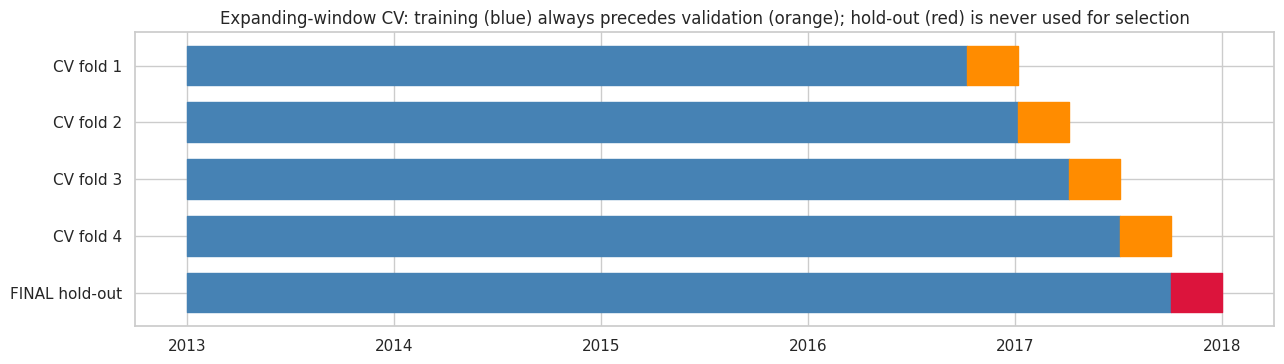

In [ ]:
# --- cv splits + hold-out ---
import matplotlib.dates as mdates

CFG.update({"n_cv_folds": 4, "cv_val_days": 90, "holdout_days": 90})


def make_splits(dates, n_folds, val_days, holdout_days, horizon_days, train_start=None):
    # folds go backwards from the end of the data. returns (folds, holdout)
    # train_start is there in case I drop the first year (lag_364 is nan there)
    # lags are at least horizon + 1 days, so a validation window longer than the horizon
    # would have features that look past train_end
    assert val_days <= horizon_days, "Validation window longer than the horizon -> leakage"

    dmin, dmax = pd.Timestamp(dates.min()), pd.Timestamp(dates.max())
    holdout_start = dmax - pd.Timedelta(days=holdout_days - 1)
    dev_end = holdout_start - pd.Timedelta(days=1)
    train_start = pd.Timestamp(train_start) if train_start else dmin

    folds = []
    for k in range(n_folds):  # fold 1 is the oldest
        val_end = dev_end - pd.Timedelta(days=(n_folds - 1 - k) * val_days)
        val_start = val_end - pd.Timedelta(days=val_days - 1)
        train_end = val_start - pd.Timedelta(days=1)
        folds.append(dict(fold=k + 1, train_start=train_start, train_end=train_end,
                          val_start=val_start, val_end=val_end))
    holdout = dict(train_start=train_start, train_end=dev_end,
                   val_start=holdout_start, val_end=dmax)

    # sanity checks on the splits
    for a, b in zip(folds[:-1], folds[1:]):
        assert a["val_end"] < b["val_start"], "Validation windows overlap"
    for f in folds:
        assert f["train_end"] < f["val_start"] <= f["val_end"] <= dev_end, "Train/val order broken"
    assert folds[-1]["val_end"] < holdout["val_start"], "CV touches the hold-out!"
    assert folds[0]["train_end"] > train_start + pd.Timedelta(days=365), "Fold 1 has <1 year of training"
    return folds, holdout


def slice_split(df, s):
    """rows for a split, picked by date"""
    tr = df[(df["date"] >= s["train_start"]) & (df["date"] <= s["train_end"])]
    va = df[(df["date"] >= s["val_start"]) & (df["date"] <= s["val_end"])]
    return tr, va


def split_summary(df, folds, holdout):
    rows = []
    for name, s in [(f"CV fold {f['fold']}", f) for f in folds] + [("FINAL hold-out", holdout)]:
        tr, va = slice_split(df, s)
        rows.append({"split": name,
                     "train": f"{s['train_start'].date()} -> {s['train_end'].date()}",
                     "validate": f"{s['val_start'].date()} -> {s['val_end'].date()}",
                     "train_rows": len(tr), "val_rows": len(va),
                     "val_days": va["date"].nunique()})
    return pd.DataFrame(rows)


def plot_splits(folds, holdout):
    fig, ax = plt.subplots(figsize=(13, 3.8))
    all_splits = folds + [holdout]
    for i, s in enumerate(all_splits):
        y = len(all_splits) - i
        is_holdout = i == len(folds)
        ax.broken_barh([(mdates.date2num(s["train_start"]), (s["train_end"] - s["train_start"]).days + 1)],
                       (y - 0.35, 0.7), color="steelblue")
        ax.broken_barh([(mdates.date2num(s["val_start"]), (s["val_end"] - s["val_start"]).days + 1)],
                       (y - 0.35, 0.7), color="crimson" if is_holdout else "darkorange")
    ax.set_yticks(range(len(all_splits), 0, -1))
    ax.set_yticklabels([f"CV fold {f['fold']}" for f in folds] + ["FINAL hold-out"])
    ax.xaxis_date()
    ax.set_title("Expanding-window CV: training (blue) always precedes validation (orange); "
                 "hold-out (red) is never used for selection")
    save_fig("05_validation_design")


folds, holdout = make_splits(feat["date"], CFG["n_cv_folds"], CFG["cv_val_days"],
                             CFG["holdout_days"], CFG["horizon_days"])
print(split_summary(feat, folds, holdout).to_string(index=False))
plot_splits(folds, holdout)

In [ ]:
# --- metrics + cv harness ---
def smape(y, p):
    """sMAPE in %. if both are 0 it counts as no error"""
    y, p = np.asarray(y, float), np.asarray(p, float)
    denom = np.abs(y) + np.abs(p)
    ratio = np.where(denom == 0, 0.0, 2 * np.abs(y - p) / np.where(denom == 0, 1, denom))
    return 100 * ratio.mean()


def metrics(y, p) -> dict:
    """MAE, RMSE, sMAPE, bias (forecast - actual, so + means over-forecast)"""
    y, p = np.asarray(y, float), np.asarray(p, float)
    e = p - y
    return {"MAE": np.abs(e).mean(), "RMSE": np.sqrt((e ** 2).mean()),
            "sMAPE": smape(y, p), "Bias": e.mean()}


def cv_evaluate(predict_fn, df, folds, name):
    # runs predict_fn(train, val) on every fold, predict_fn should only fit on train
    # keeping the oof predictions because the diagnostics and inventory parts need them
    rows, oof = [], []
    for f in folds:
        tr, va = slice_split(df, f)
        p = np.asarray(predict_fn(tr, va), float)
        assert len(p) == len(va), "predict_fn must return one prediction per validation row"
        rows.append({"model": name, "fold": f["fold"], **metrics(va["sales"], p)})
        oof.append(va[["date", "store", "item", "sales"]].assign(pred=p, fold=f["fold"], model=name))
    return pd.DataFrame(rows), pd.concat(oof, ignore_index=True)


def summarize_cv(res: pd.DataFrame) -> pd.DataFrame:
    """mean and std over the folds"""
    return res.drop(columns=["model", "fold"]).agg(["mean", "std"]).round(2)


# smoke test, just checks the harness runs. not a real baseline
def smoke_test_predictor(train_df, val_df):
    """training mean per series, only here to test the pipeline"""
    m = train_df.groupby(["store", "item"])["sales"].mean().rename("m").reset_index()
    return val_df.merge(m, on=["store", "item"], how="left")["m"].to_numpy()

res, _ = cv_evaluate(smoke_test_predictor, feat, folds, "smoke_test")
print(res.round(2))
print(summarize_cv(res))

        model  fold    MAE   RMSE  sMAPE   Bias
0  smoke_test     1  10.15  13.38  20.85  -1.08
1  smoke_test     2   9.45  12.42  21.09   3.51
2  smoke_test     3  17.56  22.60  28.64 -16.82
3  smoke_test     4  17.26  22.56  27.77 -16.22
        MAE   RMSE  sMAPE   Bias
mean  13.60  17.74  24.58  -7.65
std    4.41   5.61   4.19  10.41


In [ ]:
# --- random vs time split (optional) ---
from sklearn.ensemble import HistGradientBoostingRegressor

dev = feat[feat["date"] <= holdout["train_end"]]
honest_train, fold4_val = slice_split(feat, folds[-1])

# same eval rows for both, a random 20% of the fold 4 window
eval_rows = fold4_val.sample(frac=0.2, random_state=CFG["random_seed"])
leaky_train = dev.drop(index=eval_rows.index)  # random split style: the neighbours of the test rows
                                                   # (and later days) end up in training

def fit_and_score(train_df, test_df, n=200_000):
    train_df = train_df.sample(n=min(n, len(train_df)), random_state=CFG["random_seed"])  # sample so it runs fast on colab
    model = HistGradientBoostingRegressor(max_iter=200, random_state=CFG["random_seed"])
    model.fit(train_df[FEATURES], train_df["sales"])
    return metrics(test_df["sales"], model.predict(test_df[FEATURES]))

print("Time-ordered training :", {k: round(v, 3) for k, v in fit_and_score(honest_train, eval_rows).items()})
print("Random-split training :", {k: round(v, 3) for k, v in fit_and_score(leaky_train, eval_rows).items()})

Time-ordered training : {'MAE': np.float64(6.6), 'RMSE': np.float64(8.585), 'sMAPE': np.float64(11.252), 'Bias': np.float64(0.33)}
Random-split training : {'MAE': np.float64(6.558), 'RMSE': np.float64(8.51), 'sMAPE': np.float64(11.205), 'Bias': np.float64(0.177)}


In [ ]:
# --- baselines ---
import time, pickle, logging
from functools import partial

KEYS = ["store", "item"]
OOFS = {}  # model name -> oof predictions

def naive_last_value(train, val):
    """last value of each series, repeated"""
    last = train.sort_values("date").groupby(KEYS)["sales"].last().rename("p").reset_index()
    return val.merge(last, on=KEYS, how="left")["p"].to_numpy()

def seasonal_naive_weekly(train, val):
    """last 7 days of each series, repeated"""
    T = train["date"].max()
    last_week = train[train["date"] > T - pd.Timedelta(days=7)][KEYS + ["dow", "sales"]]
    last_week = last_week.rename(columns={"sales": "p"})
    return val.merge(last_week, on=KEYS + ["dow"], how="left")["p"].to_numpy()

def seasonal_naive_yearly(train, val, with_growth=False, window=91, clip=(0.7, 1.5)):
    """same weekday last year (364 days back), optionally scaled by recent growth"""
    ly = train[KEYS + ["date", "sales"]].copy()
    ly["date"] = ly["date"] + pd.Timedelta(days=364)  # push last year's dates forward so they line up with the val dates
    ly = ly.rename(columns={"sales": "p"})
    p = val[KEYS + ["date"]].merge(ly, on=KEYS + ["date"], how="left")["p"].to_numpy(float)
    if with_growth:
        T, d = train["date"].max(), pd.Timedelta
        recent = train[train["date"] > T - d(days=window)].groupby(KEYS)["sales"].mean()
        prior = train[(train["date"] > T - d(days=window + 364)) &
                      (train["date"] <= T - d(days=364))].groupby(KEYS)["sales"].mean()
        g = (recent / prior).clip(*clip).rename("g").reset_index()
        p = p * val[KEYS].merge(g, on=KEYS, how="left")["g"].to_numpy()
    return p

BASELINES = {
    "naive_last": naive_last_value,
    "snaive_7": seasonal_naive_weekly,
    "snaive_364": seasonal_naive_yearly,
    "snaive_364_growth": partial(seasonal_naive_yearly, with_growth=True),
}
for name, fn in BASELINES.items():
    res, OOFS[name] = cv_evaluate(fn, feat, folds, name)
    print(f"{name:20s}", res[["MAE", "RMSE", "sMAPE", "Bias"]].mean().round(2).to_dict())

naive_last           {'MAE': 12.76, 'RMSE': 16.93, 'sMAPE': 24.0, 'Bias': -2.22}
snaive_7             {'MAE': 11.13, 'RMSE': 14.67, 'sMAPE': 21.35, 'Bias': -1.1}
snaive_364           {'MAE': 8.64, 'RMSE': 11.25, 'sMAPE': 17.55, 'Bias': -2.63}
snaive_364_growth    {'MAE': 8.7, 'RMSE': 11.3, 'sMAPE': 17.28, 'Bias': 0.53}


In [ ]:
# --- mape vs smape ---
def mape(y, p):
    """MAPE in %, skips rows where actual is 0"""
    y, p = np.asarray(y, float), np.asarray(p, float)
    ok = y > 0
    return 100 * np.mean(np.abs(y[ok] - p[ok]) / y[ok])

# 1) same factor-of-2 miss, different penalty
print("actual 100, forecast 200 -> MAPE", mape([100], [200]), "% | sMAPE", round(smape([100], [200]), 1), "%")
print("actual 100, forecast  50 -> MAPE", mape([100], [50]),  "% | sMAPE", round(smape([100], [50]), 1), "%")

# 2) undefined when actual is 0
print("\nZero-sales rows in the data:", int((sales['sales'] == 0).sum()), "-> MAPE must skip them")

# 3) low volume series blow up mape even when the unit errors are small
oof = OOFS["snaive_364_growth"].copy()
vol = oof.groupby(KEYS)["sales"].transform("mean")
oof["volume_tier"] = pd.qcut(vol, 3, labels=["low", "mid", "high"])
tier = oof.groupby("volume_tier").apply(lambda g: pd.Series({
    "MAE": np.abs(g["sales"] - g["pred"]).mean(),
    "MAPE_%": mape(g["sales"], g["pred"]),
    "sMAPE_%": smape(g["sales"], g["pred"])}))
print("\nError by volume tier (seasonal naive + growth):")
print(tier.round(2))

actual 100, forecast 200 -> MAPE 100.0 % | sMAPE 66.7 %
actual 100, forecast  50 -> MAPE 50.0 % | sMAPE 66.7 %

Zero-sales rows in the data: 1 -> MAPE must skip them

Error by volume tier (seasonal naive + growth):
               MAE  MAPE_%  sMAPE_%
volume_tier                        
low           6.26   24.02    22.67
mid           8.71   16.82    16.24
high         11.15   13.24    12.90


In [ ]:
# --- ets / sarimax / prophet on a subset ---
# !pip install -q prophet  (only if the import fails)
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet

# silence cmdstanpy, it prints a line for every fit
# done after the import, not sure it works the other way round
for lg in ("cmdstanpy", "prophet"):
    logging.getLogger(lg).setLevel(logging.ERROR)
    logging.getLogger(lg).disabled = True

def pick_subset(df, n=12):
    """n series spread over the volume ranking (uses average sales only, not errors)"""
    vol = df.groupby(KEYS)["sales"].mean().sort_values()
    pos = np.linspace(0, len(vol) - 1, n).round().astype(int)
    return [tuple(int(x) for x in k) for k in vol.index[pos]]

def restrict(df, subset):
    return df[pd.MultiIndex.from_frame(df[KEYS]).isin(subset)]

SUBSET = pick_subset(sales, 12)
feat_sub = restrict(feat, SUBSET)
print("Subset (store, item):", SUBSET)

def per_series_predictor(fit_forecast):
    """wrap a one-series model so it works with cv_evaluate"""
    def predict_fn(train, val):
        out = pd.Series(np.nan, index=val.index)
        for (s, i), v in val.groupby(KEYS):
            y = train[(train["store"] == s) & (train["item"] == i)].set_index("date")["sales"].asfreq("D")
            fut = pd.DatetimeIndex(v["date"])
            assert fut[0] == y.index[-1] + pd.Timedelta(days=1), "Forecast must start right after train"
            out.loc[v.index] = np.clip(np.asarray(fit_forecast(y, fut), float), 0, None)
        return out.to_numpy()
    return predict_fn

def ets_forecast(y, fut):
    """holt-winters: damped trend + weekly seasonality (no yearly cycle)"""
    fit = ExponentialSmoothing(y, trend="add", damped_trend=True,
                               seasonal="add", seasonal_periods=7).fit()
    return fit.forecast(len(fut)).to_numpy()

def fourier_terms(dates, K=3, period=365.25):
    t = np.asarray(dates.dayofyear)
    cols = {}
    for k in range(1, K + 1):
        cols[f"sin{k}"] = np.sin(2 * np.pi * k * t / period)
        cols[f"cos{k}"] = np.cos(2 * np.pi * k * t / period)
    return pd.DataFrame(cols, index=dates)

def sarimax_forecast(y, fut):
    """weekly SARIMA + fourier terms for the yearly cycle (calendar based, so no leakage)"""
    model = SARIMAX(y, exog=fourier_terms(y.index), order=(1, 0, 1), seasonal_order=(1, 1, 1, 7),
                    enforce_stationarity=False, enforce_invertibility=False)
    fit = model.fit(disp=False, maxiter=50)  # can print convergence warnings
    return fit.forecast(len(fut), exog=fourier_terms(fut)).to_numpy()

def prophet_forecast(y, fut, mode="multiplicative"):
    m = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False,
                seasonality_mode=mode, uncertainty_samples=0)  # intervals come in the app part
    m.fit(pd.DataFrame({"ds": y.index, "y": y.to_numpy()}))
    return m.predict(pd.DataFrame({"ds": fut}))["yhat"].to_numpy()

STAT_MODELS = {
    "ets": per_series_predictor(ets_forecast),
    "sarimax_fourier": per_series_predictor(sarimax_forecast),
    "prophet_mult": per_series_predictor(prophet_forecast),
    "prophet_add": per_series_predictor(partial(prophet_forecast, mode="additive")),
}
for name, fn in STAT_MODELS.items():
    t0 = time.time()
    _, OOFS[name] = cv_evaluate(fn, feat_sub, folds, name)
    print(f"{name:18s} done in {time.time() - t0:.0f}s")

Subset (store, item): [(7, 5), (5, 23), (4, 16), (10, 23), (5, 48), (7, 35), (1, 14), (7, 28), (3, 46), (1, 13), (2, 29), (2, 28)]
ets                done in 31s


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local

sarimax_fourier    done in 471s
prophet_mult       done in 17s
prophet_add        done in 16s


In [ ]:
# --- lightgbm ---
import lightgbm as lgb

CAT_FEATURES = ["store", "item"]
LGB_PARAMS = dict(objective="regression", learning_rate=0.05, num_leaves=63, min_data_in_leaf=100,
                  feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
                  verbose=-1, seed=CFG["random_seed"], num_threads=0)
N_TREES = 300  # fixed number of trees, no early stopping on the validation fold

def make_lgbm_predictor(target="raw", params=LGB_PARAMS, n_trees=N_TREES):
    # raw: predict sales directly
    # ratio: predict sales / roll_mean_91, then multiply the level back (helps with trend)
    def predict_fn(train, val):
        if target == "ratio":
            lvl_tr = train["roll_mean_91"].to_numpy(float)
            lvl_va = val["roll_mean_91"].to_numpy(float)
            ok = np.isfinite(lvl_tr) & (lvl_tr > 0)  # drop rows with no level yet (start of each series)
            assert np.isfinite(lvl_va).all() and (lvl_va > 0).all(), "validation rows need a level"
            y = train.loc[ok, "sales"].to_numpy(float) / lvl_tr[ok]
            X, scale_va = train.loc[ok, FEATURES], lvl_va
        else:
            y, X, scale_va = train["sales"].to_numpy(float), train[FEATURES], 1.0
        model = lgb.train(params, lgb.Dataset(X, label=y, categorical_feature=CAT_FEATURES),
                          num_boost_round=n_trees)
        return np.clip(model.predict(val[FEATURES]) * scale_va, 0, None)  # no negative demand
    return predict_fn

for tgt in ["raw", "ratio"]:
    t0 = time.time()
    res, OOFS[f"lgbm_{tgt}"] = cv_evaluate(make_lgbm_predictor(tgt), feat, folds, f"lgbm_{tgt}")
    print(f"lgbm_{tgt}: {time.time() - t0:.0f}s"); print(res.round(3))

lgbm_raw: 225s
      model  fold    MAE   RMSE   sMAPE   Bias
0  lgbm_raw     1  5.888  7.734  13.147 -1.103
1  lgbm_raw     2  5.479  7.120  13.466  0.063
2  lgbm_raw     3  6.611  8.561  11.250 -1.268
3  lgbm_raw     4  6.624  8.617  11.235 -1.112
lgbm_ratio: 157s
        model  fold    MAE   RMSE   sMAPE   Bias
0  lgbm_ratio     1  5.692  7.414  12.785 -0.082
1  lgbm_ratio     2  5.670  7.330  13.768  1.963
2  lgbm_ratio     3  6.497  8.370  11.054  0.936
3  lgbm_ratio     4  6.411  8.299  10.923  0.183


=== ALL 500 SERIES (mean across 4 CV folds) ===
                      MAE  MAE_std  MAE_worst    RMSE   sMAPE   Bias
model                                                               
lgbm_ratio          6.067    0.448      6.497   7.853  12.132  0.750
lgbm_raw            6.151    0.564      6.624   8.008  12.275 -0.855
snaive_364          8.639    0.706      9.199  11.250  17.549 -2.633
snaive_364_growth   8.702    0.521      9.176  11.299  17.280  0.530
snaive_7           11.132    0.763     11.898  14.674  21.352 -1.099
naive_last         12.764    1.222     14.347  16.932  23.998 -2.220

=== 12-SERIES SUBSET: every model, same series, same folds ===
                      MAE  MAE_std  MAE_worst    RMSE   sMAPE   Bias
model                                                               
lgbm_ratio          5.958    0.365      6.440   7.755  12.371  0.656
lgbm_raw            6.134    0.504      6.780   8.088  12.571 -0.910
prophet_mult        6.339    0.334      6.730   8.367  12.93

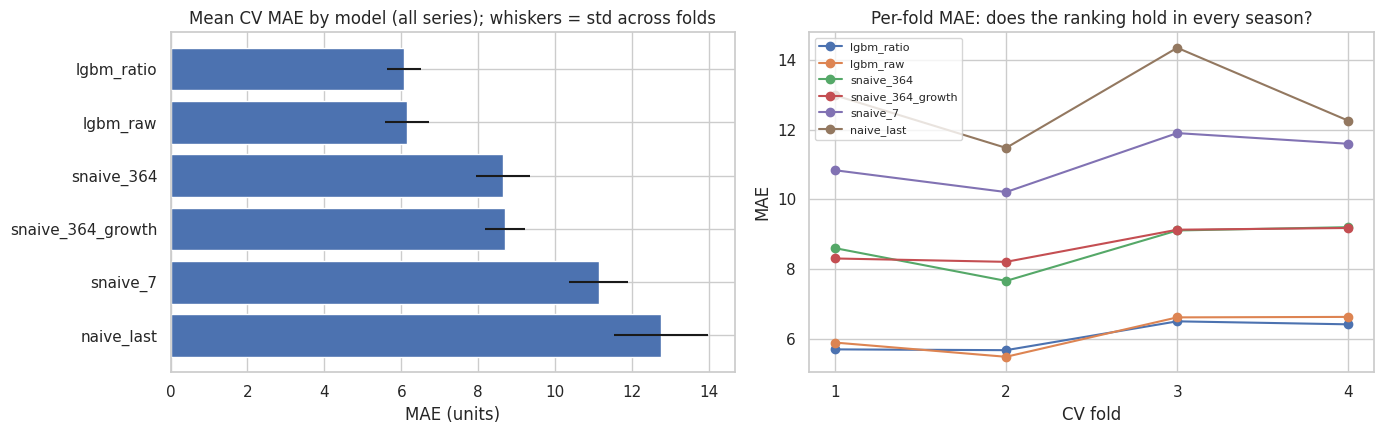

In [ ]:
# --- compare models ---
def fold_metrics(oof):
    rows = [{"model": m, "fold": f, **metrics(g["sales"], g["pred"])}
            for (m, f), g in oof.groupby(["model", "fold"])]
    return pd.DataFrame(rows)

def leaderboard(oof):
    fm = fold_metrics(oof)
    lb = fm.groupby("model").agg(MAE=("MAE", "mean"), MAE_std=("MAE", "std"), MAE_worst=("MAE", "max"),
                                 RMSE=("RMSE", "mean"), sMAPE=("sMAPE", "mean"), Bias=("Bias", "mean"))
    return lb.sort_values("MAE").round(3)

OOF_ALL = pd.concat(OOFS.values(), ignore_index=True)
ALL_SERIES = [m for m in OOFS if m not in STAT_MODELS]

print("=== ALL 500 SERIES (mean across 4 CV folds) ===")
lb_all = leaderboard(OOF_ALL[OOF_ALL["model"].isin(ALL_SERIES)])
print(lb_all)

print("\n=== 12-SERIES SUBSET: every model, same series, same folds ===")
print(leaderboard(restrict(OOF_ALL, SUBSET)))

# mean mae with fold spread, and mae per fold
fm = fold_metrics(OOF_ALL[OOF_ALL["model"].isin(ALL_SERIES)])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].barh(lb_all.index[::-1], lb_all["MAE"].to_numpy()[::-1], xerr=lb_all["MAE_std"].to_numpy()[::-1])
ax[0].set_title("Mean CV MAE by model (all series); whiskers = std across folds")
ax[0].set_xlabel("MAE (units)")
for m in lb_all.index:
    g = fm[fm["model"] == m]
    ax[1].plot(g["fold"], g["MAE"], marker="o", label=m)
ax[1].set_xticks([1, 2, 3, 4]); ax[1].set_xlabel("CV fold"); ax[1].set_ylabel("MAE")
ax[1].set_title("Per-fold MAE: does the ranking hold in every season?"); ax[1].legend(fontsize=8)
save_fig("06_model_comparison")

# save oof predictions for later
pickle.dump((OOF_ALL, SUBSET), open(PROJECT_DIR / "oof_predictions.pkl", "wb"))

In [ ]:
# --- final hold-out, run once ---
RUN_HOLDOUT = True  # only set True when everything is frozen

def evaluate_on_holdout(models, df_full, df_subset):
    """fit on all the dev data, score on the hold-out"""
    rows, preds = [], []
    for name, (fn, subset_only) in models.items():
        data = df_subset if subset_only else df_full
        tr, va = slice_split(data, holdout)  # train up to 2017-10-02, test 2017-10-03 to 12-31
        p = np.asarray(fn(tr, va), float)
        rows.append({"model": name, "n_series": va[KEYS].drop_duplicates().shape[0],
                     **metrics(va["sales"], p)})
        preds.append(va[["date", "store", "item", "sales"]].assign(pred=p, model=name))
    return pd.DataFrame(rows).round(3), pd.concat(preds, ignore_index=True)

if RUN_HOLDOUT:
    FINAL_MODELS = {
        **{n: (fn, False) for n, fn in BASELINES.items()},
        "lgbm_raw": (make_lgbm_predictor("raw"), False),
        "lgbm_ratio": (make_lgbm_predictor("ratio"), False),
        **{n: (fn, True) for n, fn in STAT_MODELS.items()},
    }
    holdout_table, holdout_preds = evaluate_on_holdout(FINAL_MODELS, feat, feat_sub)
    print(holdout_table)
    pickle.dump(holdout_preds, open(PROJECT_DIR / "holdout_predictions.pkl", "wb"))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


               model  n_series     MAE    RMSE   sMAPE   Bias
0         naive_last       500  13.270  17.653  27.470 -8.805
1           snaive_7       500  11.649  15.413  22.270  6.164
2         snaive_364       500   8.350  10.897  17.865 -2.271
3  snaive_364_growth       500   8.342  10.862  17.608 -0.125
4           lgbm_raw       500   5.963   7.763  12.535 -0.753
5         lgbm_ratio       500   5.792   7.504  12.232 -0.121
6                ets        12   9.551  13.275  18.441  4.996
7    sarimax_fourier        12   7.020   9.396  14.587  0.568
8       prophet_mult        12   6.255   8.209  13.568 -0.292
9        prophet_add        12   6.310   8.263  13.573  1.026


In [ ]:
# --- diagnostics: build the table ---
from scipy import stats

PRIMARY, REFERENCE = "lgbm_ratio", "snaive_364"

# if colab restarted, rebuild OOFS from the saved file
if "OOFS" not in globals():
    OOF_ALL, SUBSET = pickle.load(open(PROJECT_DIR / "oof_predictions.pkl", "rb"))
    OOFS = {m: g.reset_index(drop=True) for m, g in OOF_ALL.groupby("model")}

def build_diag(oofs, primary, reference):
    d = oofs[primary].copy()
    d["resid"] = d["pred"] - d["sales"]  # + = over-forecast
    d["abs_err"] = d["resid"].abs()
    d["month"] = d["date"].dt.month
    d["dow"] = d["date"].dt.dayofweek
    # days since the forecast origin (1..90), to see if error grows with distance
    d["horizon_day"] = (d["date"] - d.groupby("fold")["date"].transform("min")).dt.days + 1
    ref = oofs[reference][KEYS + ["date", "pred"]].rename(columns={"pred": "ref_pred"})
    n0 = len(d)
    d = d.merge(ref, on=KEYS + ["date"], how="left", validate="one_to_one")
    assert len(d) == n0 and d["ref_pred"].notna().all(), "reference predictions misaligned"
    d["ref_abs_err"] = (d["ref_pred"] - d["sales"]).abs()
    return d

d = build_diag(OOFS, PRIMARY, REFERENCE)
print(d.shape)  # should be (180000, 14)

(180000, 14)


                    mean_pred  resid_std  poisson_std  dispersion
pred                                                             
(8.115, 23.691]         18.99       4.39         4.36        1.01
(23.691, 30.878]        27.34       5.31         5.23        1.02
(30.878, 38.021]        34.41       5.98         5.87        1.02
(38.021, 45.63]         41.78       6.58         6.46        1.02
(45.63, 53.802]         49.69       7.21         7.05        1.02
(53.802, 62.689]        58.21       7.78         7.63        1.02
(62.689, 72.633]        67.53       8.37         8.22        1.02
(72.633, 84.724]        78.41       9.02         8.85        1.02
(84.724, 102.668]       92.98       9.79         9.64        1.02
(102.668, 191.009]     121.48      11.23        11.02        1.02
Standardised errors: skew=-0.181, excess kurtosis=0.108


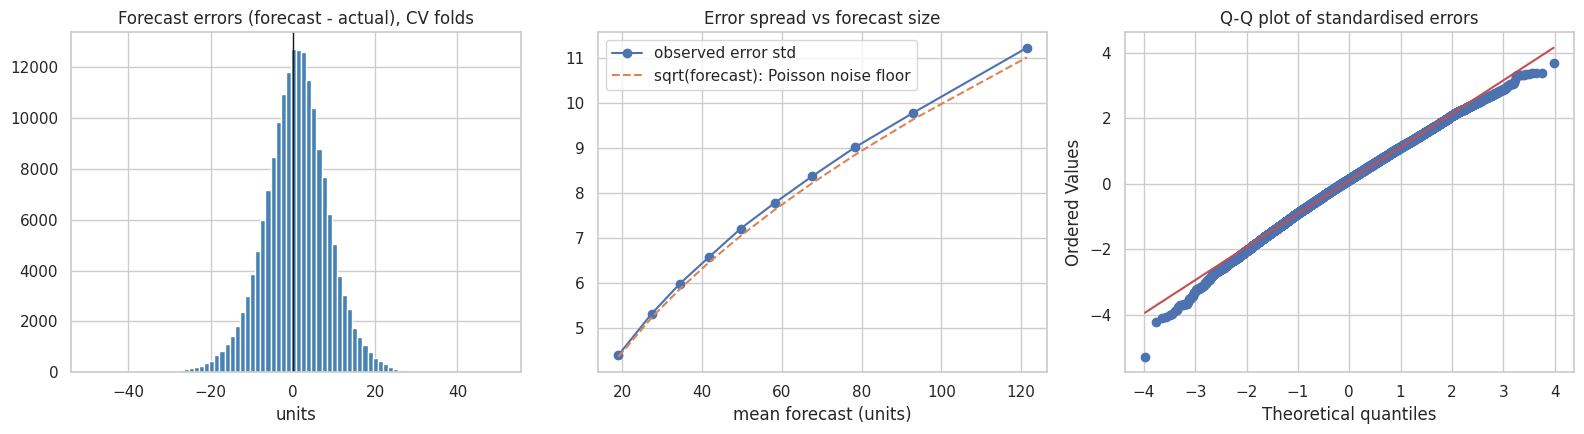

In [ ]:
# --- is the error just noise? ---
def noise_level_table(d, n_bins=10):
    # error spread by forecast size vs sqrt(forecast), which is the std of poisson noise
    # dispersion around 1 means the errors are about as small as count noise allows
    b = pd.qcut(d["pred"], n_bins, duplicates="drop")
    t = d.groupby(b, observed=True).agg(mean_pred=("pred", "mean"), resid_std=("resid", "std"),
                                         resid_mean=("resid", "mean"), n=("resid", "size"))
    t["poisson_std"] = np.sqrt(t["mean_pred"])
    t["dispersion"] = t["resid_std"] / t["poisson_std"]
    return t

nl = noise_level_table(d)
print(nl[["mean_pred", "resid_std", "poisson_std", "dispersion"]].round(2).to_string())

z = d["resid"] / np.sqrt(d["pred"].clip(lower=1))  # error scaled by sqrt(forecast)
print(f"Standardised errors: skew={stats.skew(z):.3f}, excess kurtosis={stats.kurtosis(z):.3f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].hist(d["resid"], bins=80, color="steelblue", edgecolor="white"); ax[0].axvline(0, color="k", lw=1)
ax[0].set_title("Forecast errors (forecast - actual), CV folds"); ax[0].set_xlabel("units")
ax[1].plot(nl["mean_pred"], nl["resid_std"], marker="o", label="observed error std")
ax[1].plot(nl["mean_pred"], nl["poisson_std"], ls="--", label="sqrt(forecast): Poisson noise floor")
ax[1].set_title("Error spread vs forecast size"); ax[1].set_xlabel("mean forecast (units)"); ax[1].legend()
stats.probplot(z.sample(20000, random_state=CFG["random_seed"]), dist="norm", plot=ax[2])
ax[2].set_title("Q-Q plot of standardised errors")
save_fig("07_residual_shape")

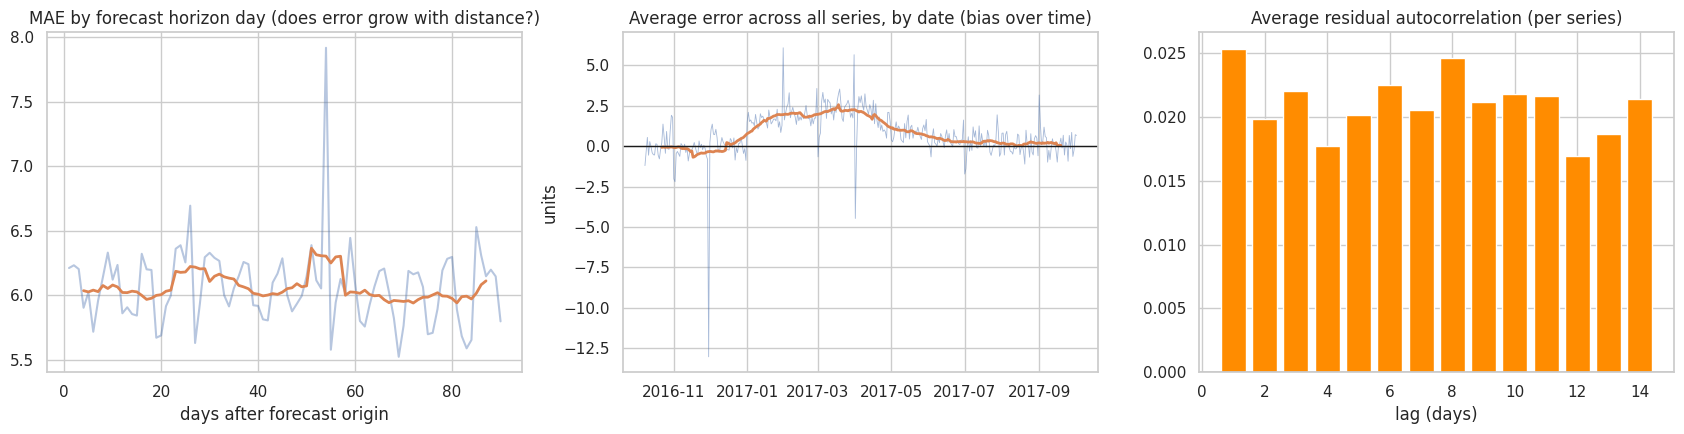

Mean pairwise error correlation between series: 0.0274
Std of the all-series daily average error: 1.373 | expected if series errors were independent: 0.34


In [ ]:
# --- horizon, bias over time, autocorrelation ---
h = d.groupby("horizon_day").agg(MAE=("abs_err", "mean"), Bias=("resid", "mean"))
daily_mean = d.groupby("date")["resid"].mean()
wide = d.pivot_table(index="date", columns=KEYS, values="resid")  # date x series
lags = list(range(1, 15))
acf = [np.nanmean([wide[c].autocorr(k) for c in wide.columns]) for k in lags]  # averaged over series

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(h.index, h["MAE"], alpha=.4); ax[0].plot(h["MAE"].rolling(7, center=True).mean(), lw=2)
ax[0].set_title("MAE by forecast horizon day (does error grow with distance?)")
ax[0].set_xlabel("days after forecast origin")
ax[1].plot(daily_mean.index, daily_mean.values, lw=.6, alpha=.5)
ax[1].plot(daily_mean.rolling(28, center=True).mean(), lw=2); ax[1].axhline(0, color="k", lw=1)
ax[1].set_title("Average error across all series, by date (bias over time)"); ax[1].set_ylabel("units")
ax[2].bar(lags, acf, color="darkorange"); ax[2].axhline(0, color="k", lw=1)
ax[2].set_title("Average residual autocorrelation (per series)"); ax[2].set_xlabel("lag (days)")
save_fig("08_residual_time")

cm = wide.corr().to_numpy(); n = len(cm)
print("Mean pairwise error correlation between series:", round((cm.sum() - n) / (n * n - n), 4))
print("Std of the all-series daily average error:", round(daily_mean.std(), 3),
      "| expected if series errors were independent:", round(wide.std().mean() / np.sqrt(n), 3))


=== STORE ===
             n    MAE  WAPE_%   Bias  skill_vs_ref
store                                             
1      18000.0  5.817  11.014  0.699         0.295
2      18000.0  6.966   9.313  0.951         0.304
3      18000.0  6.494   9.773  0.936         0.295
4      18000.0  6.311  10.294  0.781         0.296
5      18000.0  5.276  11.867  0.546         0.302
6      18000.0  5.249  11.838  0.513         0.295
7      18000.0  5.045  12.422  0.433         0.295
8      18000.0  6.766   9.455  0.963         0.300
9      18000.0  6.277  10.215  0.802         0.294
10     18000.0  6.473   9.879  0.877         0.299

=== MONTH ===
             n    MAE  WAPE_%   Bias  skill_vs_ref
month                                             
1      15500.0  5.116  12.845  1.715         0.255
2      14000.0  5.493  12.375  1.988         0.267
3      15500.0  6.095  11.484  2.347         0.257
4      15000.0  6.505  10.393  1.679         0.268
5      15500.0  6.409   9.733  0.899         0.289
6

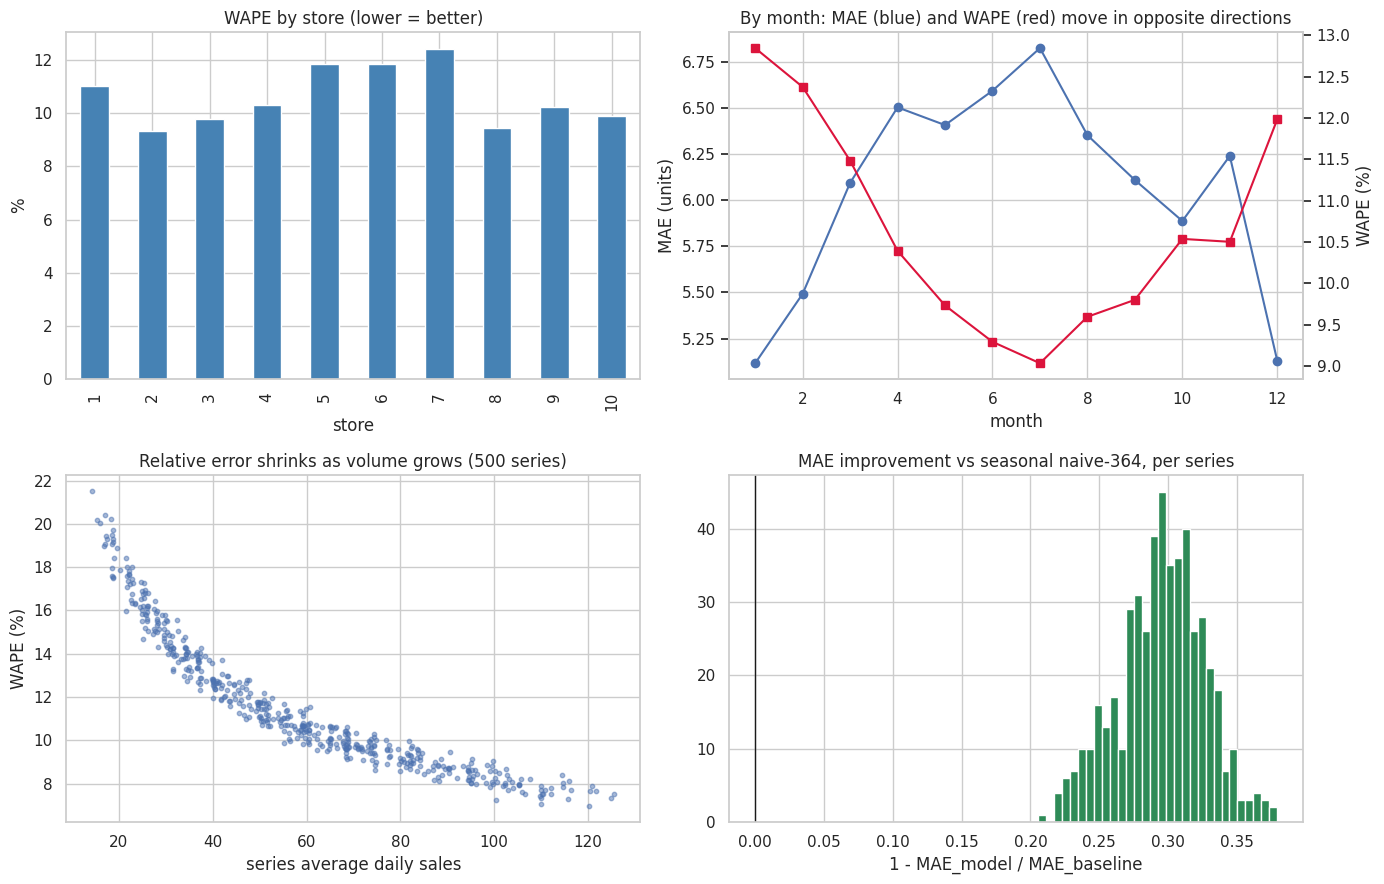


Series where the model is WORSE than the baseline: 0


In [ ]:
# --- error by segment ---
def segment_table(d, by):
    # wape = sum|error| / sum(actual), like mape but weighted by volume
    # skill_vs_ref = 1 - mae_model / mae_baseline (0.30 = 30% lower mae)
    def f(x):
        return pd.Series({"n": len(x), "MAE": x["abs_err"].mean(),
                          "WAPE_%": 100 * x["abs_err"].sum() / x["sales"].sum(),
                          "Bias": x["resid"].mean(),
                          "skill_vs_ref": 1 - x["abs_err"].mean() / x["ref_abs_err"].mean()})
    return d.groupby(by).apply(f)

by_store, by_month, by_dow, by_item, by_series = [segment_table(d, k) for k in ["store", "month", "dow", "item", KEYS]]
for name, t in [("STORE", by_store), ("MONTH", by_month), ("WEEKDAY (0=Mon)", by_dow)]:
    print(f"\n=== {name} ==="); print(t.round(3))
print("\nBest / worst items by WAPE:")
print(by_item.sort_values("WAPE_%").iloc[[0, 1, 2, -3, -2, -1]].round(2))

vol = d.groupby(KEYS)["sales"].mean()  # same (store, item) order as by_series
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
by_store["WAPE_%"].plot.bar(ax=ax[0, 0], color="steelblue")
ax[0, 0].set_title("WAPE by store (lower = better)"); ax[0, 0].set_ylabel("%")
by_month["MAE"].plot(ax=ax[0, 1], marker="o"); ax[0, 1].set_ylabel("MAE (units)")
a2 = ax[0, 1].twinx(); by_month["WAPE_%"].plot(ax=a2, marker="s", color="crimson"); a2.set_ylabel("WAPE (%)"); a2.grid(False)
ax[0, 1].set_title("By month: MAE (blue) and WAPE (red) move in opposite directions")
ax[1, 0].scatter(vol.to_numpy(), by_series["WAPE_%"].to_numpy(), s=10, alpha=.5)
ax[1, 0].set_xlabel("series average daily sales"); ax[1, 0].set_ylabel("WAPE (%)")
ax[1, 0].set_title("Relative error shrinks as volume grows (500 series)")
ax[1, 1].hist(by_series["skill_vs_ref"], bins=30, color="seagreen", edgecolor="white"); ax[1, 1].axvline(0, color="k", lw=1)
ax[1, 1].set_title("MAE improvement vs seasonal naive-364, per series"); ax[1, 1].set_xlabel("1 - MAE_model / MAE_baseline")
save_fig("09_error_segments")
print("\nSeries where the model is WORSE than the baseline:", int((by_series["skill_vs_ref"] < 0).sum()))

LightGBM gain importance (% of total):
doy_cos              60.56
week_of_year          9.44
dow                   6.38
doy_sin               5.98
dow_sin               5.57
month                 4.67
day_of_year           2.65
dow_cos               1.40
trend_ratio_28_91     0.98
is_weekend            0.93
dtype: float64

Share of mean |SHAP| by feature group (%):
calendar             93.7
identity              2.6
rolling_level_vol     2.2
derived               1.1
lags                  0.4
holiday               0.0
dtype: float64


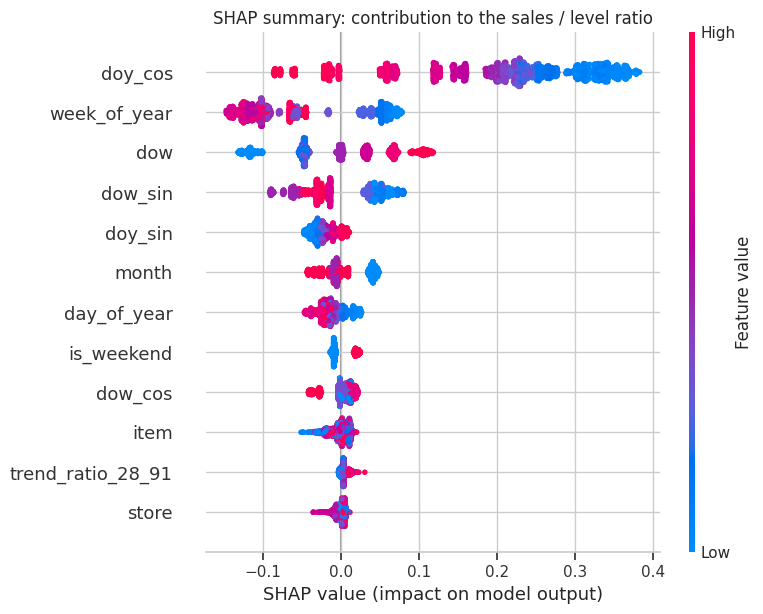

In [ ]:
# --- feature importance / shap (fold 4) ---
# !pip install -q shap  (only if the import fails)
import shap

def fit_ratio_model(train, features=None, params=LGB_PARAMS, n_trees=N_TREES):
    """same recipe as lgbm_ratio but returns the model so I can look inside"""
    features = features or FEATURES
    lvl = train["roll_mean_91"].to_numpy(float)
    ok = np.isfinite(lvl) & (lvl > 0)
    X, y = train.loc[ok, features], train.loc[ok, "sales"].to_numpy(float) / lvl[ok]
    cats = [c for c in CAT_FEATURES if c in features]
    return lgb.train(params, lgb.Dataset(X, label=y, categorical_feature=cats), num_boost_round=n_trees)

tr4, va4 = slice_split(feat, folds[-1])
model = fit_ratio_model(tr4)

gain = pd.Series(model.feature_importance("gain"), index=FEATURES)
print("LightGBM gain importance (% of total):"); print((100 * gain / gain.sum()).sort_values(ascending=False).round(2).head(10))

sample = va4.sample(3000, random_state=CFG["random_seed"])  # sample of rows so shap is quick
sv = shap.TreeExplainer(model).shap_values(sample[FEATURES])
mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=FEATURES)

GROUPS = {"identity": ["store", "item"],
          "calendar": ["dow", "is_weekend", "day_of_month", "week_of_year", "month", "quarter", "day_of_year",
                       "is_month_start", "is_month_end", "dow_sin", "dow_cos", "doy_sin", "doy_cos"],
          "holiday": ["is_us_holiday"],
          "lags": [c for c in FEATURES if c.startswith("lag_")],
          "rolling_level_vol": [c for c in FEATURES if c.startswith("roll_")],
          "derived": ["same_dow_mean_4", "trend_ratio_28_91"]}
assert sorted(sum(GROUPS.values(), [])) == sorted(FEATURES), "every feature must belong to exactly one group"
grp = pd.Series({k: mean_abs[v].sum() for k, v in GROUPS.items()})
print("\nShare of mean |SHAP| by feature group (%):"); print((100 * grp / grp.sum()).sort_values(ascending=False).round(1))

plt.figure()
shap.summary_plot(sv, sample[FEATURES], max_display=12, show=False)
plt.title("SHAP summary: contribution to the sales / level ratio")
save_fig("10_shap_summary")

In [ ]:
# --- ablations: do holiday / lag features matter? ---
def predict_ratio(train, val, features):
    m = fit_ratio_model(train, features=features)
    return np.clip(m.predict(val[features]) * val["roll_mean_91"].to_numpy(float), 0, None)

def ablation_cv(name, drop):
    feats = [c for c in FEATURES if c not in drop]
    t0 = time.time()
    res, _ = cv_evaluate(lambda tr, va: predict_ratio(tr, va, feats), feat, folds, name)
    print(f"{name}: dropped {len(drop)} feature(s) in {time.time() - t0:.0f}s")
    print(res[["MAE", "RMSE", "sMAPE", "Bias"]].mean().round(3).to_dict())

ablation_cv("no_holiday", ["is_us_holiday"])
ablation_cv("no_lags", [c for c in FEATURES if c.startswith("lag_")])
print("Reference (full model, from Cell 20): MAE 6.067, RMSE 7.853, sMAPE 12.132, Bias 0.750")

no_holiday: dropped 1 feature(s) in 171s
{'MAE': 6.071, 'RMSE': 7.857, 'sMAPE': 12.136, 'Bias': 0.768}
no_lags: dropped 6 feature(s) in 139s
{'MAE': 6.071, 'RMSE': 7.858, 'sMAPE': 12.138, 'Bias': 0.749}
Reference (full model, from Cell 20): MAE 6.067, RMSE 7.853, sMAPE 12.132, Bias 0.750


In [ ]:
# --- save per-series error stats ---
g = d.groupby(KEYS)
series_stats = pd.DataFrame({"n_obs": g.size(), "mean_sales": g["sales"].mean(),
                             "resid_std": g["resid"].std(), "resid_mean": g["resid"].mean(),
                             "MAE": g["abs_err"].mean()}).reset_index()
series_stats.to_pickle(PROJECT_DIR / "series_error_stats.pkl")
d.to_pickle(PROJECT_DIR / "diagnostic_table.pkl")
print(series_stats.shape)  # should be (500, 7)
print(series_stats.head(3).round(2))

(500, 7)
   store  item  n_obs  mean_sales  resid_std  resid_mean   MAE
0      1     1    360       22.14       4.88        0.36  3.92
1      1     2    360       59.14       8.36        0.30  6.59
2      1     3    360       37.18       6.18        0.26  4.80


In [ ]:
# --- business assumptions (placeholders, not real numbers) ---
ASSUMPTIONS = {
    "lead_time_days": 7,  # days from order to arrival
    "review_period_days": 7,  # days between orders
    "service_level": 0.95,  # chance of no stockout per cycle
    "unit_holding_cost_per_day": 0.05,  # $ per unit per day
    "unit_stockout_cost": 5.00,  # $ lost per unit short (margin + goodwill)
}
CFG["assumptions"] = ASSUMPTIONS  # reused in the app
A = ASSUMPTIONS

def optimal_service_level(h_per_day, s, R):
    """cost-optimal service level, s / (s + h*R). an unsold unit sits about R days per cycle"""
    return s / (s + h_per_day * R)

print("Cost-optimal cycle service level under these assumptions:",
      round(optimal_service_level(A["unit_holding_cost_per_day"], A["unit_stockout_cost"],
                                   A["review_period_days"]), 4))

Cost-optimal cycle service level under these assumptions: 0.9346


In [ ]:
# --- calibrate errors on cv, load the hold-out ---
from scipy import stats

MODELS = ["naive_last", "snaive_364", "snaive_364_growth", "lgbm_raw", "lgbm_ratio"]
KEYS = ["store", "item"]
L, R = A["lead_time_days"], A["review_period_days"]

# hold-out predictions from the hold-out cell
HOLDOUT = holdout_preds if "holdout_preds" in globals() else pickle.load(
    open(PROJECT_DIR / "holdout_predictions.pkl", "rb"))

def to_wide(df, col):
    """pivot to date x (store, item) with the columns in a fixed order"""
    return df.pivot(index="date", columns=KEYS, values=col).sort_index(axis=1)

def calibrate_errors(oof_model, windows):
    # per series: mean daily error (bias) and std of the k-day sum of errors
    # the k-day sum is what safety stock has to cover
    d = oof_model.assign(resid=oof_model["pred"] - oof_model["sales"])
    resid = to_wide(d, "resid")
    assert (resid.index.to_series().diff().dropna().dt.days == 1).all(), "need a contiguous daily history"
    out = {"bias": resid.mean(), "sigma_1": resid.std()}
    for k in windows:
        out[f"sigma_{k}"] = resid.rolling(k, min_periods=k).sum().std()
    return pd.DataFrame(out)

# calibration only uses cv residuals (Oct 2016 - Oct 2017), not the hold-out
CALIB = {m: calibrate_errors(OOF_ALL[OOF_ALL["model"] == m], [L, R, L + R]) for m in MODELS}

def test_matrices(preds, models):
    D = to_wide(preds[preds["model"] == models[0]], "sales")
    F = {}
    for m in models:
        w = to_wide(preds[preds["model"] == m], "pred")
        assert w.shape == D.shape and w.columns.equals(D.columns), f"{m}: series/date mismatch"
        F[m] = w.to_numpy(float)
    return D.to_numpy(float), F, D.columns

D, F, SERIES = test_matrices(HOLDOUT, MODELS)
for m in MODELS:
    assert CALIB[m].index.equals(SERIES), f"{m}: calibration series order differs"
print("Hold-out matrix (days x series):", D.shape)  # should be (90, 500)

c = CALIB["lgbm_ratio"]
print("Calibration summary (lgbm_ratio):"); print(c.describe().round(2).loc[["mean", "min", "max"]])
print("Empirical sigma_(L+R) vs independence shortcut:",
      float((c[f"sigma_{L + R}"] / (c["sigma_1"] * np.sqrt(L + R))).mean().round(3)))

Hold-out matrix (days x series): (90, 500)
Calibration summary (lgbm_ratio):
      bias  sigma_1  sigma_7  sigma_14
mean  0.75     7.60    21.34     31.98
min  -0.35     3.86     9.57     12.94
max   2.27    12.08    37.57     63.85
Empirical sigma_(L+R) vs independence shortcut: 1.119


In [ ]:
# --- safety stock + reorder points ---
def safety_and_reorder(model, A, calib=None, F=None):
    # per-series policy numbers at the start of the hold-out
    # safety stock = z * sigma(L+R), S = forecast over L+R days + safety stock
    # reorder point = forecast over the lead time + z * sigma(L)
    calib, F = calib or CALIB, F or globals()["F"]
    L, R = A["lead_time_days"], A["review_period_days"]
    z = stats.norm.ppf(A["service_level"])
    cal = calib[model]
    out = pd.DataFrame({"avg_daily_forecast": F[model].mean(axis=0),
                        "sigma_lead_review": cal[f"sigma_{L + R}"].to_numpy(),
                        "sigma_lead": cal[f"sigma_{L}"].to_numpy()}, index=cal.index)
    out["safety_stock"] = z * out["sigma_lead_review"]
    out["order_up_to_S"] = F[model][:L + R].sum(axis=0) + out["safety_stock"]
    out["reorder_point"] = F[model][:L].sum(axis=0) + z * out["sigma_lead"]
    return out

SS = {m: safety_and_reorder(m, A) for m in MODELS}
tot = pd.DataFrame({m: {"total_safety_stock_units": SS[m]["safety_stock"].sum(),
                        "mean_sigma_L+R": SS[m]["sigma_lead_review"].mean()} for m in MODELS}).T
tot["vs_snaive_364_%"] = 100 * (tot["total_safety_stock_units"] / tot.loc["snaive_364", "total_safety_stock_units"] - 1)
print(tot.round(1))

# 3 example series (low / mid / high volume)
vol = SS["lgbm_ratio"]["avg_daily_forecast"].sort_values()
examples = vol.index[np.linspace(0, len(vol) - 1, 3).round().astype(int)]
pd.set_option("display.width", 200)
print(pd.concat({m: SS[m].loc[examples] for m in ["lgbm_ratio", "snaive_364"]}).round(1))

                   total_safety_stock_units  mean_sigma_L+R  vs_snaive_364_%
naive_last                         123026.4           149.6            266.2
snaive_364                          33594.1            40.8              0.0
snaive_364_growth                   37582.7            45.7             11.9
lgbm_raw                            25353.2            30.8            -24.5
lgbm_ratio                          26300.4            32.0            -21.7
                       avg_daily_forecast  sigma_lead_review  sigma_lead  safety_stock  order_up_to_S  reorder_point
           store item                                                                                               
lgbm_ratio 7     5                   13.2               12.9         9.6          21.3          214.4          111.6
           3     39                  52.5               29.9        20.6          49.2          821.5          419.5
           2     15                 118.1               60.2        37

In [ ]:
# --- inventory simulation ---
def simulate_policy(F, D, ss, L, R, h, s):
    # periodic review order-up-to policy with lost sales
    # F and D are days x series. each day: arrivals come in, order if it's a review day, demand hits, count end of day stock
    # an order placed on day t arrives on day t+L, forecast sums stop at the end of the window
    T, N = D.shape
    assert L >= 1 and R >= 1 and F.shape == D.shape and ss.shape == (N,)
    cs = np.vstack([np.zeros((1, N)), np.cumsum(F, axis=0)])  # cumulative forecasts
    def fsum(a, b):  # forecast total for days a..b-1
        b = min(b, T)
        return cs[b] - cs[a] if b > a else np.zeros(N)

    on_hand = fsum(0, L + R) + ss  # day 0 starts fully stocked
    arrivals = np.zeros((T + L + 1, N))
    hold_units, lost, served = (np.zeros(N) for _ in range(3))
    stockout_in_cycle = np.zeros((int(np.ceil(T / R)), N), dtype=bool)
    for t in range(T):
        on_hand = on_hand + arrivals[t]
        if t > 0 and t % R == 0:  # review day
            inv_position = on_hand + arrivals[t + 1:].sum(axis=0)  # on hand + on order
            q = np.maximum(0.0, fsum(t, t + L + R) + ss - inv_position)
            arrivals[t + L] += q
        sold = np.minimum(D[t], on_hand)
        short = D[t] - sold
        on_hand = on_hand - sold
        hold_units += on_hand; lost += short; served += sold
        stockout_in_cycle[t // R] |= short > 1e-9
    return {"demand": D.sum(axis=0), "served": served, "lost": lost, "hold_units": hold_units,
            "cycle_ok": 1 - stockout_in_cycle.mean(axis=0)}

def summarize(sim, h, s, ss, n_days):
    out = {"fill_rate_%": 100 * sim["served"].sum() / sim["demand"].sum(),
           "cycle_service_%": 100 * sim["cycle_ok"].mean(),
           "avg_inventory_units": sim["hold_units"].sum() / n_days,
           "safety_stock_units": ss.sum(),
           "holding_cost": h * sim["hold_units"].sum(),
           "stockout_cost": s * sim["lost"].sum()}
    out["total_cost"] = out["holding_cost"] + out["stockout_cost"]
    return out

def run_policy(model, A, debias=False, F=None, D=None):
    """calibrate + simulate one model (debias=True removes each series cv bias)"""
    F, D = F or globals()["F"], D if D is not None else globals()["D"]
    L, R = A["lead_time_days"], A["review_period_days"]
    z = stats.norm.ppf(A["service_level"])
    cal = CALIB[model]
    ss = z * cal[f"sigma_{L + R}"].to_numpy()
    Fm = np.clip(F[model] - (cal["bias"].to_numpy() if debias else 0.0), 0, None)
    sim = simulate_policy(Fm, D, ss, L, R, A["unit_holding_cost_per_day"], A["unit_stockout_cost"])
    return summarize(sim, A["unit_holding_cost_per_day"], A["unit_stockout_cost"], ss, D.shape[0])

RESULTS = pd.DataFrame({m: run_policy(m, A) for m in MODELS}).T
RESULTS["cost_vs_snaive_364_%"] = 100 * (RESULTS["total_cost"] / RESULTS.loc["snaive_364", "total_cost"] - 1)
print("ASSUMPTION-BASED SIMULATION at a common service-level target "
      f"({A['service_level']:.0%}); NOT real savings")
print(RESULTS.round(1).to_string())

ASSUMPTION-BASED SIMULATION at a common service-level target (95%); NOT real savings
                   fill_rate_%  cycle_service_%  avg_inventory_units  safety_stock_units  holding_cost  stockout_cost  total_cost  cost_vs_snaive_364_%
naive_last                98.0             83.9             160391.0            123026.4      721759.3       247552.7    969312.0                  56.3
snaive_364                99.2             86.3             117112.3             33594.1      527005.5        93256.4    620262.0                   0.0
snaive_364_growth         99.8             96.2             134944.8             37582.7      607251.6        19797.6    627049.2                   1.1
lgbm_raw                  99.7             92.9             118332.2             25353.2      532494.9        35268.7    567763.6                  -8.5
lgbm_ratio                99.9             96.4             123468.1             26300.4      555606.6        14434.9    570041.5                  -8.1


COST AT >=95% ACHIEVED CYCLE SERVICE (assumption-based simulation; z picked per model for comparison only)
                   z_needed  cycle_service_%  holding_cost  stockout_cost  total_cost  cost_vs_snaive_364_%
naive_last              2.5             95.6      992702.8        48224.3   1040927.1                  69.3
snaive_364              2.4             95.7      591092.0        23671.7    614763.6                   0.0
snaive_364_growth       1.6             95.8      602799.6        21900.9    624700.5                   1.6
lgbm_raw                1.9             95.3      549217.4        22541.7    571759.0                  -7.0
lgbm_ratio              1.5             95.3      545583.1        19667.5    565250.6                  -8.1


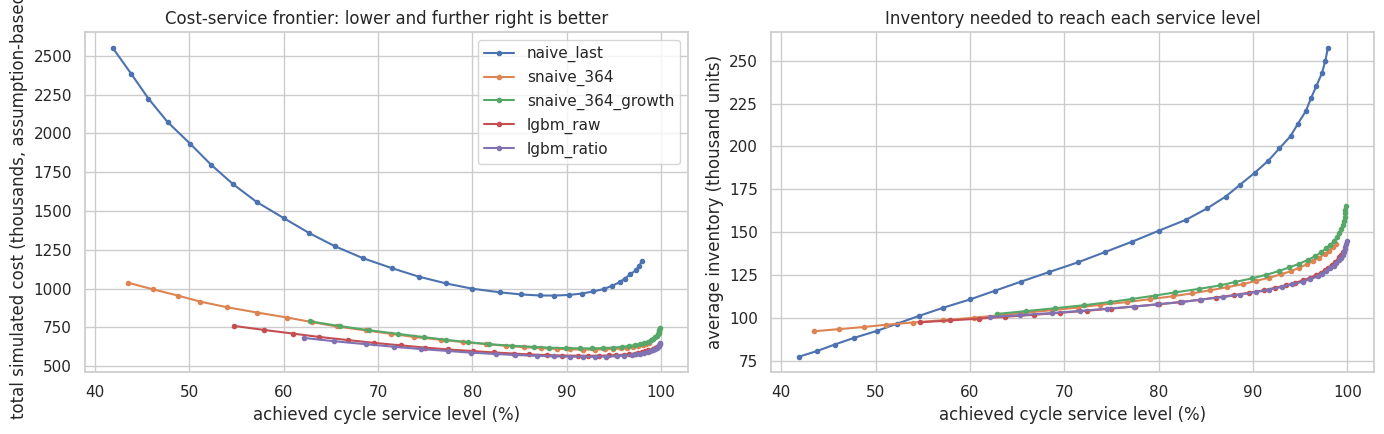

In [ ]:
# --- compare at the same achieved service ---
def frontier(model, A, z_grid=np.linspace(0, 3, 31)):
    """try a range of z values, record service and cost for each"""
    rows = []
    for z in z_grid:
        r = run_policy(model, {**A, "service_level": float(stats.norm.cdf(z))})
        r["z"] = z; rows.append(r)
    return pd.DataFrame(rows)

FR = {m: frontier(m, A) for m in MODELS}

def matched_cost(fr, target_pct=95.0):
    ok = fr[fr["cycle_service_%"] >= target_pct]  # first z that reaches the target
    return ok.iloc[0] if len(ok) else None

rows = {m: matched_cost(FR[m]) for m in MODELS}
matched = pd.DataFrame({m: {"z_needed": r["z"], "cycle_service_%": r["cycle_service_%"],
                            "holding_cost": r["holding_cost"], "stockout_cost": r["stockout_cost"],
                            "total_cost": r["total_cost"]}
                        for m, r in rows.items() if r is not None}).T
matched["cost_vs_snaive_364_%"] = 100 * (matched["total_cost"] / matched.loc["snaive_364", "total_cost"] - 1)
print("COST AT >=95% ACHIEVED CYCLE SERVICE (assumption-based simulation; z picked per model for comparison only)")
print(matched.round(1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for m in MODELS:
    ax[0].plot(FR[m]["cycle_service_%"], FR[m]["total_cost"] / 1e3, marker=".", label=m)
    ax[1].plot(FR[m]["cycle_service_%"], FR[m]["avg_inventory_units"] / 1e3, marker=".", label=m)
ax[0].set_xlabel("achieved cycle service level (%)"); ax[0].set_ylabel("total simulated cost (thousands, assumption-based)")
ax[0].set_title("Cost-service frontier: lower and further right is better"); ax[0].legend()
ax[1].set_xlabel("achieved cycle service level (%)"); ax[1].set_ylabel("average inventory (thousand units)")
ax[1].set_title("Inventory needed to reach each service level")
save_fig("11_cost_service_frontier")

In [ ]:
# --- sensitivity to the cost assumption ---
rows = []
for s_ in [2, 5, 10, 20]:  # stockout cost per unit
    for sl in [0.90, 0.95, 0.98]:  # service target
        a = {**A, "unit_stockout_cost": s_, "service_level": sl}
        base_c = run_policy("snaive_364", a)["total_cost"]
        new_c = run_policy("lgbm_ratio", a)["total_cost"]
        rows.append({"stockout_cost": s_, "service_target": sl, "change_%": 100 * (new_c / base_c - 1)})
sens = pd.DataFrame(rows).pivot(index="stockout_cost", columns="service_target", values="change_%")
print("lgbm_ratio total cost vs snaive_364 (%; negative = cheaper). Assumption-based simulation.")
print(sens.round(1))

lgbm_ratio total cost vs snaive_364 (%; negative = cheaper). Assumption-based simulation.
service_target  0.90  0.95  0.98
stockout_cost                   
2               -3.5  -0.5   1.2
5              -14.7  -8.1  -2.9
10             -27.6 -18.1  -8.9
20             -42.5 -31.9 -18.8


In [ ]:
# --- save for the app ---
pickle.dump({"calibration": CALIB["lgbm_ratio"], "assumptions": ASSUMPTIONS, "series": list(SERIES)},
            open(PROJECT_DIR / "calibration_lgbm_ratio.pkl", "wb"))
RESULTS.to_csv(PROJECT_DIR / "inventory_results_target_service.csv")
matched.to_csv(PROJECT_DIR / "inventory_results_matched_service.csv")
sens.to_csv(PROJECT_DIR / "inventory_sensitivity.csv")
print("saved")

saved


In [ ]:
# --- interval coverage on the hold-out ---
def interval_coverage(preds, sigma_1, levels=(0.80, 0.90, 0.95)):
    """share of hold-out days inside forecast +/- z*sigma_1 (sigma comes from cv, so it is out of sample)"""
    F = to_wide(preds, "pred").to_numpy(float)
    A_ = to_wide(preds, "sales").to_numpy(float)
    sig = sigma_1.to_numpy()
    rows = {}
    for lvl in levels:
        z = stats.norm.ppf(0.5 + lvl / 2)
        lo, hi = np.clip(F - z * sig, 0, None), F + z * sig
        rows[f"{lvl:.0%}"] = {"coverage": ((A_ >= lo) & (A_ <= hi)).mean(),
                              "below_%": 100 * (A_ < lo).mean(), "above_%": 100 * (A_ > hi).mean(),
                              "avg_width_units": (hi - lo).mean()}
    return pd.DataFrame(rows).T

hp = HOLDOUT[HOLDOUT["model"] == "lgbm_ratio"]
assert CALIB["lgbm_ratio"].index.equals(to_wide(hp, "pred").columns), "series order mismatch"
cov = interval_coverage(hp, CALIB["lgbm_ratio"]["sigma_1"])
print(cov.round(3))
INTERVAL_COVERAGE = {k: float(v) for k, v in cov["coverage"].items()}  # goes into metrics.json for the app

     coverage  below_%  above_%  avg_width_units
80%     0.820    8.360    9.627           19.476
90%     0.912    3.740    5.033           24.997
95%     0.958    1.633    2.564           29.786


In [ ]:
# --- refit on all data, forecast 2018 Q1 ---
def make_future_panel(sales_df, horizon):
    """add `horizon` empty future days (sales = nan) for every series, keeps the panel complete and sorted"""
    last = sales_df["date"].max()
    future_dates = pd.date_range(last + pd.Timedelta(days=1), periods=horizon, freq="D")
    fut = sales_df[KEYS].drop_duplicates().merge(pd.DataFrame({"date": future_dates}), how="cross")
    fut["sales"] = np.float32("nan")
    hist = sales_df.assign(sales=sales_df["sales"].astype("float32"))
    panel = pd.concat([hist, fut], ignore_index=True).sort_values(KEYS + ["date"]).reset_index(drop=True)
    return panel, last

panel, LAST_OBS = make_future_panel(sales, CFG["horizon_days"])
pf = build_features(panel)
is_future = pf["date"] > LAST_OBS

# checks: future rows have every feature (lags >= 91 days only need known data)
# and adding the future rows didn't change the old features
assert pf.loc[is_future, FEATURES].notna().all().all(), "NaN features in the forecast window"
assert np.allclose(pf.loc[~is_future, FEATURES].to_numpy("float64"),
                   feat[FEATURES].to_numpy("float64"), equal_nan=True), "history features changed"

fc_values = make_lgbm_predictor("ratio")(pf[~is_future], pf[is_future])  # takes about 40 s
forecast = pf.loc[is_future, ["date", "store", "item"]].assign(forecast=np.round(fc_values, 3))
print(forecast.shape, forecast["date"].min().date(), "->", forecast["date"].max().date())
print(forecast["forecast"].describe().round(1))

(45000, 4) 2018-01-01 -> 2018-03-31
count    45000.0
mean        48.8
std         24.4
min          8.2
25%         28.8
50%         45.2
75%         64.5
max        146.9
Name: forecast, dtype: float64


In [ ]:
# --- export files for the app ---
import json

APP_DIR = PROJECT_DIR / "app"
ART = APP_DIR / "artifacts"
ART.mkdir(parents=True, exist_ok=True)

# 1) forecasts
forecast.to_csv(ART / "forecast.csv", index=False)

# 2) last 365 days of history (for the chart and last year's line)
hist = sales[sales["date"] > LAST_OBS - pd.Timedelta(days=365)][["date", "store", "item", "sales"]]
hist.to_csv(ART / "history_last365.csv.gz", index=False)

# 3) error calibration from all out-of-sample residuals (cv + hold-out, 450 days in a row)
cols = ["date", "store", "item", "sales", "pred"]
cal_df = pd.concat([OOF_ALL[OOF_ALL["model"] == "lgbm_ratio"][cols],
                    HOLDOUT[HOLDOUT["model"] == "lgbm_ratio"][cols]], ignore_index=True)
resid = to_wide(cal_df.assign(r=cal_df["pred"] - cal_df["sales"]), "r")
assert (resid.index.to_series().diff().dropna().dt.days == 1).all(), "calibration history must be contiguous"

cal = pd.DataFrame({"bias": resid.mean()})
for k in range(1, 31):  # std of the k-day sum of errors
    cal[f"sigma_{k}"] = resid.rolling(k, min_periods=k).sum().std()
cal["mean_sales"] = to_wide(cal_df, "sales").mean()
cal.reset_index().to_csv(ART / "calibration.csv", index=False)

# 4) metrics + assumptions for the about panel (computed, not typed by hand)
tr_, va_ = slice_split(feat, holdout)
metrics_out = {
    "holdout_period": f"{holdout['val_start'].date()} to {holdout['val_end'].date()}",
    "lgbm_ratio": {k: float(v) for k, v in metrics(hp["sales"], hp["pred"]).items()},
    "seasonal_naive_364": {k: float(v) for k, v in metrics(va_["sales"], seasonal_naive_yearly(tr_, va_)).items()},
    "interval_coverage": INTERVAL_COVERAGE,
    "forecast_start": str(forecast["date"].min().date()), "forecast_end": str(forecast["date"].max().date()),
    "calibration_days": int(len(resid)),
}
(ART / "metrics.json").write_text(json.dumps(metrics_out, indent=2))
(ART / "assumptions.json").write_text(json.dumps(ASSUMPTIONS, indent=2))
print({p.name: f"{p.stat().st_size / 1e6:.2f} MB" for p in ART.iterdir()})

{'forecast.csv': '1.03 MB', 'history_last365.csv.gz': '0.67 MB', 'calibration.csv': '0.30 MB', 'metrics.json': '0.00 MB', 'assumptions.json': '0.00 MB'}


In [ ]:
%%writefile /content/drive/MyDrive/demand_forecasting/app/app.py
"""Streamlit app: forecast + recommended order for a store/item. Reads the precomputed files in artifacts/.
Run with: streamlit run app.py"""
import json
import math
from pathlib import Path
from statistics import NormalDist

import altair as alt
import pandas as pd
import streamlit as st

ARTIFACTS = Path(__file__).parent / "artifacts"
KEYS = ["store", "item"]

st.set_page_config(page_title="Demand Forecast & Inventory Support", layout="wide")


# ---- load data ----
@st.cache_data
def load_artifacts():
    forecast = pd.read_csv(ARTIFACTS / "forecast.csv", parse_dates=["date"])
    history = pd.read_csv(ARTIFACTS / "history_last365.csv.gz", parse_dates=["date"])
    calib = pd.read_csv(ARTIFACTS / "calibration.csv").set_index(KEYS)
    metrics = json.loads((ARTIFACTS / "metrics.json").read_text())
    assumptions = json.loads((ARTIFACTS / "assumptions.json").read_text())
    return forecast, history, calib, metrics, assumptions


forecast_all, history_all, calib, metrics, defaults = load_artifacts()


# ---- calculations ----
def interval_bounds(fc: pd.DataFrame, sigma_1: float, level: float) -> pd.DataFrame:
    """forecast +/- z * sigma_1 for a single day (sigma_1 = std of out-of-sample errors)"""
    z = NormalDist().inv_cdf(0.5 + level / 2)
    out = fc.copy()
    out["lower"] = (out["forecast"] - z * sigma_1).clip(lower=0)  # can't be negative
    out["upper"] = out["forecast"] + z * sigma_1
    return out


def recommend_order(fc_values, i0, lead, review, z, sigma_lr, sigma_l, on_hand, on_order, pack):
    # order-up-to policy
    # S = forecast over lead + review days + z * sigma(lead + review)
    # order = max(0, S - (on hand + on order)), rounded up to the pack size
    horizon = lead + review
    demand_lr = float(fc_values[i0:i0 + horizon].sum())
    demand_l = float(fc_values[i0:i0 + lead].sum())
    safety = z * sigma_lr
    s_level = demand_lr + safety
    position = on_hand + on_order
    raw = max(0.0, s_level - position)
    qty = math.ceil(raw / pack) * pack if raw > 0 else 0
    return {"demand_lr": demand_lr, "safety_stock": safety, "order_up_to": s_level,
            "position": position, "raw": raw, "qty": int(qty), "reorder_point": demand_l + z * sigma_l}


# ---- sidebar ----
st.sidebar.header("1. Pick a series")
stores = sorted(forecast_all["store"].unique())
items = sorted(forecast_all["item"].unique())
store = st.sidebar.selectbox("Store", stores, index=0)
item = st.sidebar.selectbox("Item", items, index=0)

st.sidebar.header("2. Forecast interval")
level_label = st.sidebar.radio("Prediction interval", ["80%", "90%", "95%"], index=0, horizontal=True)
level = int(level_label.strip("%")) / 100

st.sidebar.header("3. Inventory policy")
lead = st.sidebar.slider("Lead time (days)", 1, 14, int(defaults["lead_time_days"]))
review = st.sidebar.slider("Review period (days)", 1, 14, int(defaults["review_period_days"]))
service = st.sidebar.slider("Target service level", 0.80, 0.995, float(defaults["service_level"]), 0.005,
                            help="Probability of no stockout during a replenishment cycle.")

st.sidebar.header("4. Current stock")
on_hand = st.sidebar.number_input("Units on hand", min_value=0.0, value=100.0, step=10.0)
on_order = st.sidebar.number_input("Units already on order", min_value=0.0, value=0.0, step=10.0)
pack = st.sidebar.number_input("Pack size (order multiple)", min_value=1, value=1, step=1)

with st.sidebar.expander("Cost assumptions (illustrative)"):
    hold_cost = st.number_input("Holding cost, $ per unit per day", min_value=0.001,
                                value=float(defaults["unit_holding_cost_per_day"]), step=0.01, format="%.3f")
    stock_cost = st.number_input("Stockout cost, $ per unit", min_value=0.01,
                                 value=float(defaults["unit_stockout_cost"]), step=0.5)
suggested = stock_cost / (stock_cost + hold_cost * review)

# ---- data for the selected series ----
fc = (forecast_all[(forecast_all["store"] == store) & (forecast_all["item"] == item)]
      .sort_values("date").reset_index(drop=True))
hist = history_all[(history_all["store"] == store) & (history_all["item"] == item)].sort_values("date")
cal = calib.loc[(store, item)]
fc = interval_bounds(fc, float(cal["sigma_1"]), level)

# same weekday last year (364 days back), the seasonal naive line
fc["last_year"] = hist.set_index("date")["sales"].reindex(fc["date"] - pd.Timedelta(days=364)).to_numpy()

n_days = len(fc)
max_i0 = n_days - (lead + review)  # protection interval has to fit inside the forecast window
order_dates = list(fc["date"].dt.date[: max_i0 + 1])

# ---- page ----
st.title("Retail Demand Forecast & Inventory Decision Support")
st.info("**Demonstration only.** The dataset has no prices, costs, stock levels or lead times, so the policy "
        "inputs and cost figures are illustrative assumptions you can change. Forecasts are 90 days ahead.")

order_date = st.sidebar.selectbox("Order date (review day)", order_dates, index=0,
                                  help="The protection interval starts here.")
i0 = order_dates.index(order_date)

z = NormalDist().inv_cdf(service)
rec = recommend_order(fc["forecast"].to_numpy(), i0, lead, review, z,
                      float(cal[f"sigma_{lead + review}"]), float(cal[f"sigma_{lead}"]),
                      on_hand, on_order, int(pack))

st.subheader(f"Store {store} · Item {item}")
c1, c2, c3, c4 = st.columns(4)
c1.metric(f"Forecast demand, next {lead + review} days", f"{rec['demand_lr']:.0f} units")
c2.metric("Safety stock", f"{rec['safety_stock']:.0f} units")
c3.metric("Order-up-to level", f"{rec['order_up_to']:.0f} units")
c4.metric("Recommended order", f"{rec['qty']} units")

if rec["qty"] == 0:
    st.success(f"No order needed: inventory position ({rec['position']:.0f}) already covers the "
               f"order-up-to level ({rec['order_up_to']:.0f}).")
else:
    st.warning(f"Order **{rec['qty']} units** on {order_date}: order-up-to level {rec['order_up_to']:.0f} "
               f"minus inventory position {rec['position']:.0f}.")
st.caption(f"Reorder point (continuous-review view): {rec['reorder_point']:.0f} units. "
           f"With your cost inputs, the cost-optimal service level would be about {suggested:.1%} "
           f"(s / (s + h·R)); you selected {service:.1%}.")

# ---- chart ----
recent = hist.tail(120)
lines = pd.concat([
    recent.assign(series="Actual sales (history)").rename(columns={"sales": "value"})[["date", "value", "series"]],
    fc.assign(series="Forecast").rename(columns={"forecast": "value"})[["date", "value", "series"]],
    fc.assign(series="Same weekday last year").rename(columns={"last_year": "value"})[["date", "value", "series"]],
])
color = alt.Color("series:N", scale=alt.Scale(
    domain=["Actual sales (history)", "Forecast", "Same weekday last year"],
    range=["#4c78a8", "#e45756", "#9d9d9d"]), legend=alt.Legend(title=None, orient="bottom"))
base = alt.Chart(lines).encode(x=alt.X("date:T", title=None))
line_layer = base.mark_line().encode(
    y=alt.Y("value:Q", title="Units per day"), color=color,
    strokeDash=alt.condition(alt.datum.series == "Same weekday last year", alt.value([4, 3]), alt.value([1, 0])))
band = alt.Chart(fc).mark_area(opacity=0.2, color="#e45756").encode(
    x="date:T", y=alt.Y("lower:Q"), y2="upper:Q")
window = pd.DataFrame({"start": [fc["date"].iloc[i0]],
                       "end": [fc["date"].iloc[i0 + lead + review - 1] + pd.Timedelta(days=1)]})
shade = alt.Chart(window).mark_rect(opacity=0.12, color="#54a24b").encode(x="start:T", x2="end:T")
st.altair_chart((shade + band + line_layer).properties(
    height=380, title=f"Daily sales and {level_label} prediction interval; green = protection interval "
                      f"({lead + review} days from order date)").interactive(), width="stretch")

# ---- details ----
with st.expander("How this recommendation is calculated"):
    st.markdown(
        f"""
1. **Forecast** daily demand with a LightGBM model (predicts sales relative to a recent level), trained on 2013-2017.
2. **Interval:** forecast ± z × σ, where σ = {cal['sigma_1']:.2f} units is the std of this series' *out-of-sample* daily errors.
3. **Protection interval** = lead time + review period = **{lead + review} days**. Forecast demand over it: **{rec['demand_lr']:.0f}**.
4. **Safety stock** = z × σ({lead + review}-day error) = {z:.2f} × {float(cal[f'sigma_{lead + review}']):.1f} = **{rec['safety_stock']:.0f}** units.
   σ is measured on *summed* multi-day errors, not scaled from the daily value.
5. **Order-up-to level** = demand + safety stock = **{rec['order_up_to']:.0f}**.
6. **Order** = max(0, level − (on hand + on order)) = max(0, {rec['order_up_to']:.0f} − {rec['position']:.0f}),
   rounded up to the pack size = **{rec['qty']}** units.
        """)

with st.expander("Forecast table"):
    table = fc[["date", "forecast", "lower", "upper", "last_year"]].copy()
    table[["forecast", "lower", "upper", "last_year"]] = table[["forecast", "lower", "upper", "last_year"]].round(1)
    st.dataframe(table, width="stretch", hide_index=True)
    st.download_button("Download CSV", table.to_csv(index=False), file_name=f"forecast_store{store}_item{item}.csv")

with st.expander("Model accuracy and limitations"):
    m, b = metrics["lgbm_ratio"], metrics["seasonal_naive_364"]
    st.markdown(f"**Hold-out ({metrics['holdout_period']}, all 500 series, never used for model selection):**")
    st.table(pd.DataFrame({"LightGBM": m, "Seasonal naive (364d)": b}).loc[["MAE", "RMSE", "sMAPE", "Bias"]].round(2))
    cov = metrics.get("interval_coverage")
    if cov:
        st.markdown("**Interval check on the hold-out (nominal vs. observed coverage):** " +
                    ", ".join(f"{k}: {v:.1%}" for k, v in cov.items()))
    st.markdown("""
**Limitations.** No real cost, price, stock or lead-time data (all inputs are assumptions). Sales are treated as demand,
so any past stockouts understate true demand. Forecasts are 90 days ahead; a live system would use fresher data.
The dataset behaves like clean, count-noise data, so accuracy here probably overstates what real retail data would give.
Safety stock assumes roughly normal errors and one lead time per series.
        """)

Overwriting /content/drive/MyDrive/demand_forecasting/app/app.py


In [ ]:
%%writefile /content/drive/MyDrive/demand_forecasting/app/requirements.txt
streamlit>=1.66.0
pandas

Overwriting /content/drive/MyDrive/demand_forecasting/app/requirements.txt


In [ ]:
# --- save result tables for the repo ---
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

def holdout_metrics_table(preds):
    rows = [{"model": m, "n_series": g[KEYS].drop_duplicates().shape[0], **metrics(g["sales"], g["pred"])}
            for m, g in preds.groupby("model")]
    return pd.DataFrame(rows).set_index("model").round(3).sort_values("MAE")

holdout_metrics_table(HOLDOUT).to_csv(RESULTS_DIR / "holdout_metrics_all_series.csv")
sub = holdout_metrics_table(restrict(HOLDOUT, SUBSET))  # same 12 series for every model
sub.to_csv(RESULTS_DIR / "holdout_metrics_subset12.csv")
leaderboard(OOF_ALL[OOF_ALL["model"].isin(ALL_SERIES)]).to_csv(RESULTS_DIR / "cv_leaderboard_all_series.csv")
leaderboard(restrict(OOF_ALL, SUBSET)).to_csv(RESULTS_DIR / "cv_leaderboard_subset12.csv")
print(sub)  # hold-out comparison on the 12 series

                   n_series     MAE    RMSE   sMAPE    Bias
model                                                      
lgbm_ratio               12   5.590   7.319  12.261  -0.217
lgbm_raw                 12   5.915   7.812  12.734  -1.027
prophet_mult             12   6.255   8.209  13.568  -0.292
prophet_add              12   6.310   8.263  13.573   1.026
sarimax_fourier          12   7.020   9.396  14.587   0.568
snaive_364_growth        12   8.307  10.756  17.954  -0.534
snaive_364               12   8.422  11.029  18.331  -3.019
ets                      12   9.551  13.275  18.441   4.996
snaive_7                 12  11.854  16.138  23.175   5.674
naive_last               12  15.812  21.485  31.700 -12.731
